### Introduction 

In [1]:

# 1. import essental libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import StratifiedKFold

from sklearn import preprocessing
from sklearn import impute
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from mlxtend.plotting import plot_decision_regions
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
import sklearn.metrics as M
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay


train = pd.read_csv(
    "/kaggle/input/competitions/playground-series-s4e11/train.csv"
)

test = pd.read_csv(
    "/kaggle/input/competitions/playground-series-s4e11/test.csv"
)


In [2]:
train.columns = [
    "id",
    "name",
    "gender",
    "age",
    "city",
    "work_status",
    "profession",
    "academic_pressure",
    "work_pressure",
    "cgpa",
    "study_satisfaction",
    "job_satisfaction",
    "sleep_duration",
    "dietary_habits",
    "degree",
    "suicidal_thoughts",
    "work_study_hours",
    "financial_stress",
    "family_history_mental_illness",
    "depression"
]
test.columns = [
    "id",
    "name",
    "gender",
    "age",
    "city",
    "work_status",
    "profession",
    "academic_pressure",
    "work_pressure",
    "cgpa",
    "study_satisfaction",
    "job_satisfaction",
    "sleep_duration",
    "dietary_habits",
    "degree",
    "suicidal_thoughts",
    "work_study_hours",
    "financial_stress",
    "family_history_mental_illness"
]

In [3]:
train.info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140700 entries, 0 to 140699
Data columns (total 20 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   id                             140700 non-null  int64  
 1   name                           140700 non-null  object 
 2   gender                         140700 non-null  object 
 3   age                            140700 non-null  float64
 4   city                           140700 non-null  object 
 5   work_status                    140700 non-null  object 
 6   profession                     104070 non-null  object 
 7   academic_pressure              27897 non-null   float64
 8   work_pressure                  112782 non-null  float64
 9   cgpa                           27898 non-null   float64
 10  study_satisfaction             27897 non-null   float64
 11  job_satisfaction               112790 non-null  float64
 12  sleep_duration                

In [4]:
categorical_columns = train.select_dtypes(
    include=["object"]
).columns

numerical_columns = train.select_dtypes(
    include=["int64", "float64"]
).columns

ordinal_columns = [
    "academic_pressure",
    "work_pressure",
    "study_satisfaction",
    "job_satisfaction",
    "financial_stress"
]

print("Categorical Columns:")
print(categorical_columns.tolist())

print("\nNumerical Columns:")
print(numerical_columns.tolist())

print("\nOrdinal Columns:")
print(ordinal_columns)

Categorical Columns:
['name', 'gender', 'city', 'work_status', 'profession', 'sleep_duration', 'dietary_habits', 'degree', 'suicidal_thoughts', 'family_history_mental_illness']

Numerical Columns:
['id', 'age', 'academic_pressure', 'work_pressure', 'cgpa', 'study_satisfaction', 'job_satisfaction', 'work_study_hours', 'financial_stress', 'depression']

Ordinal Columns:
['academic_pressure', 'work_pressure', 'study_satisfaction', 'job_satisfaction', 'financial_stress']


### Exploratory Data Analysis (EDA)

In [5]:
train.describe (include = "all")

,id,name,gender,age,city,work_status,profession,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,sleep_duration,dietary_habits,degree,suicidal_thoughts,work_study_hours,financial_stress,family_history_mental_illness,depression
count,140700.000000,140700,140700,140700.000000,140700,140700,104070,27897.000000,112782.000000,27898.000000,27897.000000,112790.000000,140700,140696,140698,140700,140700.000000,140696.000000,140700,140700.000000
unique,NaN,422,2,NaN,98,2,64,NaN,NaN,NaN,NaN,NaN,36,23,115,2,NaN,NaN,2,NaN
top,NaN,Rohan,Male,NaN,Kalyan,Working Professional,Teacher,NaN,NaN,NaN,NaN,NaN,Less than 5 hours,Moderate,Class 12,No,NaN,NaN,No,NaN
freq,NaN,3178,77464,NaN,6591,112799,24906,NaN,NaN,NaN,NaN,NaN,38784,49705,14729,71138,NaN,NaN,70758,NaN
mean,70349.500000,NaN,NaN,40.388621,NaN,NaN,NaN,3.142273,2.998998,7.658636,2.944940,2.974404,NaN,NaN,NaN,NaN,6.252679,2.988983,NaN,0.181713
std,40616.735775,NaN,NaN,12.384099,NaN,NaN,NaN,1.380457,1.405771,1.464466,1.360197,1.416078,NaN,NaN,NaN,NaN,3.853615,1.413633,NaN,0.385609
min,0.000000,NaN,NaN,18.000000,NaN,NaN,NaN,1.000000,1.000000,5.030000,1.000000,1.000000,NaN,NaN,NaN,NaN,0.000000,1.000000,NaN,0.000000
25%,35174.750000,NaN,NaN,29.000000,NaN,NaN,NaN,2.000000,2.000000,6.290000,2.000000,2.000000,NaN,NaN,NaN,NaN,3.000000,2.000000,NaN,0.000000
50%,70349.500000,NaN,NaN,42.000000,NaN,NaN,NaN,3.000000,3.000000,7.770000,3.000000,3.000000,NaN,NaN,NaN,NaN,6.000000,3.000000,NaN,0.000000
75%,105524.250000,NaN,NaN,51.000000,NaN,NaN,NaN,4.000000,4.000000,8.920000,4.000000,4.000000,NaN,NaN,NaN,NaN,10.000000,4.000000,NaN,0.000000


In [6]:
for col in categorical_columns:
    if col not in ["name", "id"]:
        unique_values = train[col].dropna().unique().tolist()
        
        print(f"\n{col}:")
        print(f"{len(unique_values)} unique values")
        print(sorted(unique_values, key=str))




for col in ordinal_columns:
    unique_values = train[col].dropna().unique().tolist()
    
    print(f"\n{col}:")
    print(f"{len(unique_values)} unique values")
    print(sorted(unique_values))


gender:
2 unique values
['Female', 'Male']

city:
98 unique values
['3.0', 'Aaradhya', 'Aditya', 'Agra', 'Ahmedabad', 'Aishwarya', 'Anvi', 'Armaan', 'Atharv', 'Ayansh', 'Ayush', 'Bangalore', 'Bhavna', 'Bhopal', 'Chennai', 'Chhavi', 'City', 'Delhi', 'Dhruv', 'Faridabad', 'Galesabad', 'Gaurav', 'Ghaziabad', 'Gurgaon', 'Harsh', 'Harsha', 'Hyderabad', 'Indore', 'Ishanabad', 'Ishkarsh', 'Ithal', 'Itheg', 'Ivaan', 'Jaipur', 'Jhanvi', 'Kagan', 'Kalyan', 'Kanpur', 'Kashish', 'Kashk', 'Keshav', 'Khaziabad', 'Khushi', 'Kibara', 'Kolkata', 'Krinda', 'Krishna', 'Less Delhi', 'Less than 5 Kalyan', 'Lucknow', 'Ludhiana', 'M.Com', 'M.Tech', 'MCA', 'ME', 'MSc', 'Mahi', 'Malyansh', 'Meerut', 'Mihir', 'Mira', 'Molkata', 'Moreadhyay', 'Morena', 'Mumbai', 'Nagpur', 'Nalini', 'Nalyan', 'Nandini', 'Nashik', 'No', 'Parth', 'Patna', 'Plata', 'Pooja', 'Pratyush', 'Pune', 'Raghavendra', 'Rajkot', 'Rashi', 'Researcher', 'Reyansh', 'Saanvi', 'Shrey', 'Srinagar', 'Surat', 'Thane', 'Tolkata', 'Tushar', 'Unirar', '

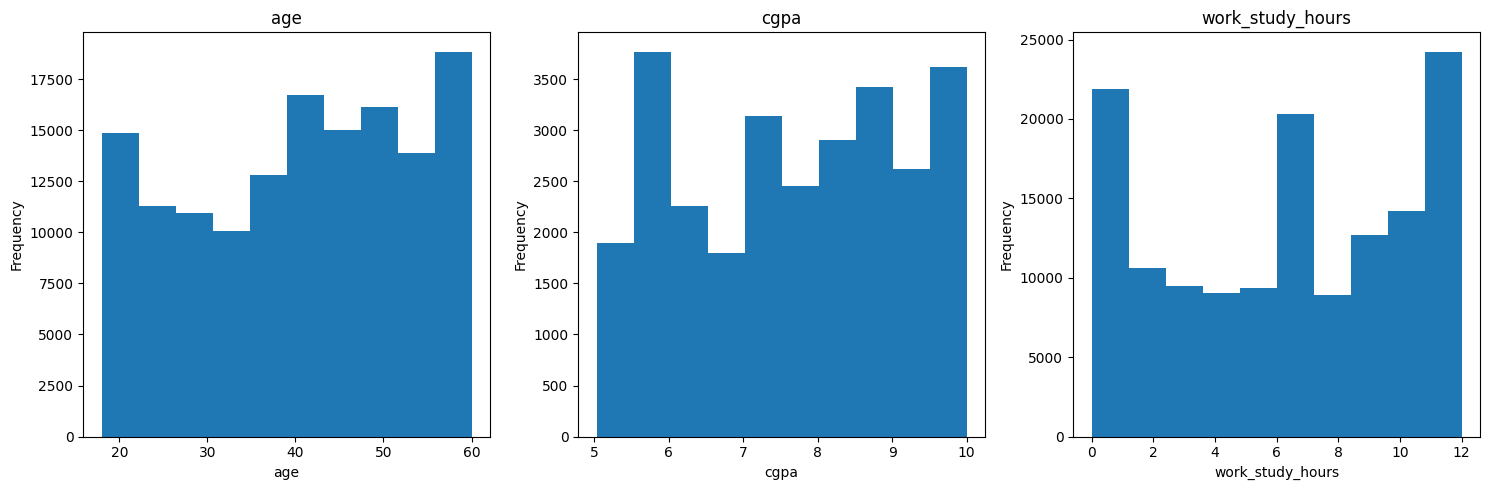

In [7]:
numeric_cols = [
    "age",
    "cgpa",
    "work_study_hours"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(train[col].dropna())
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

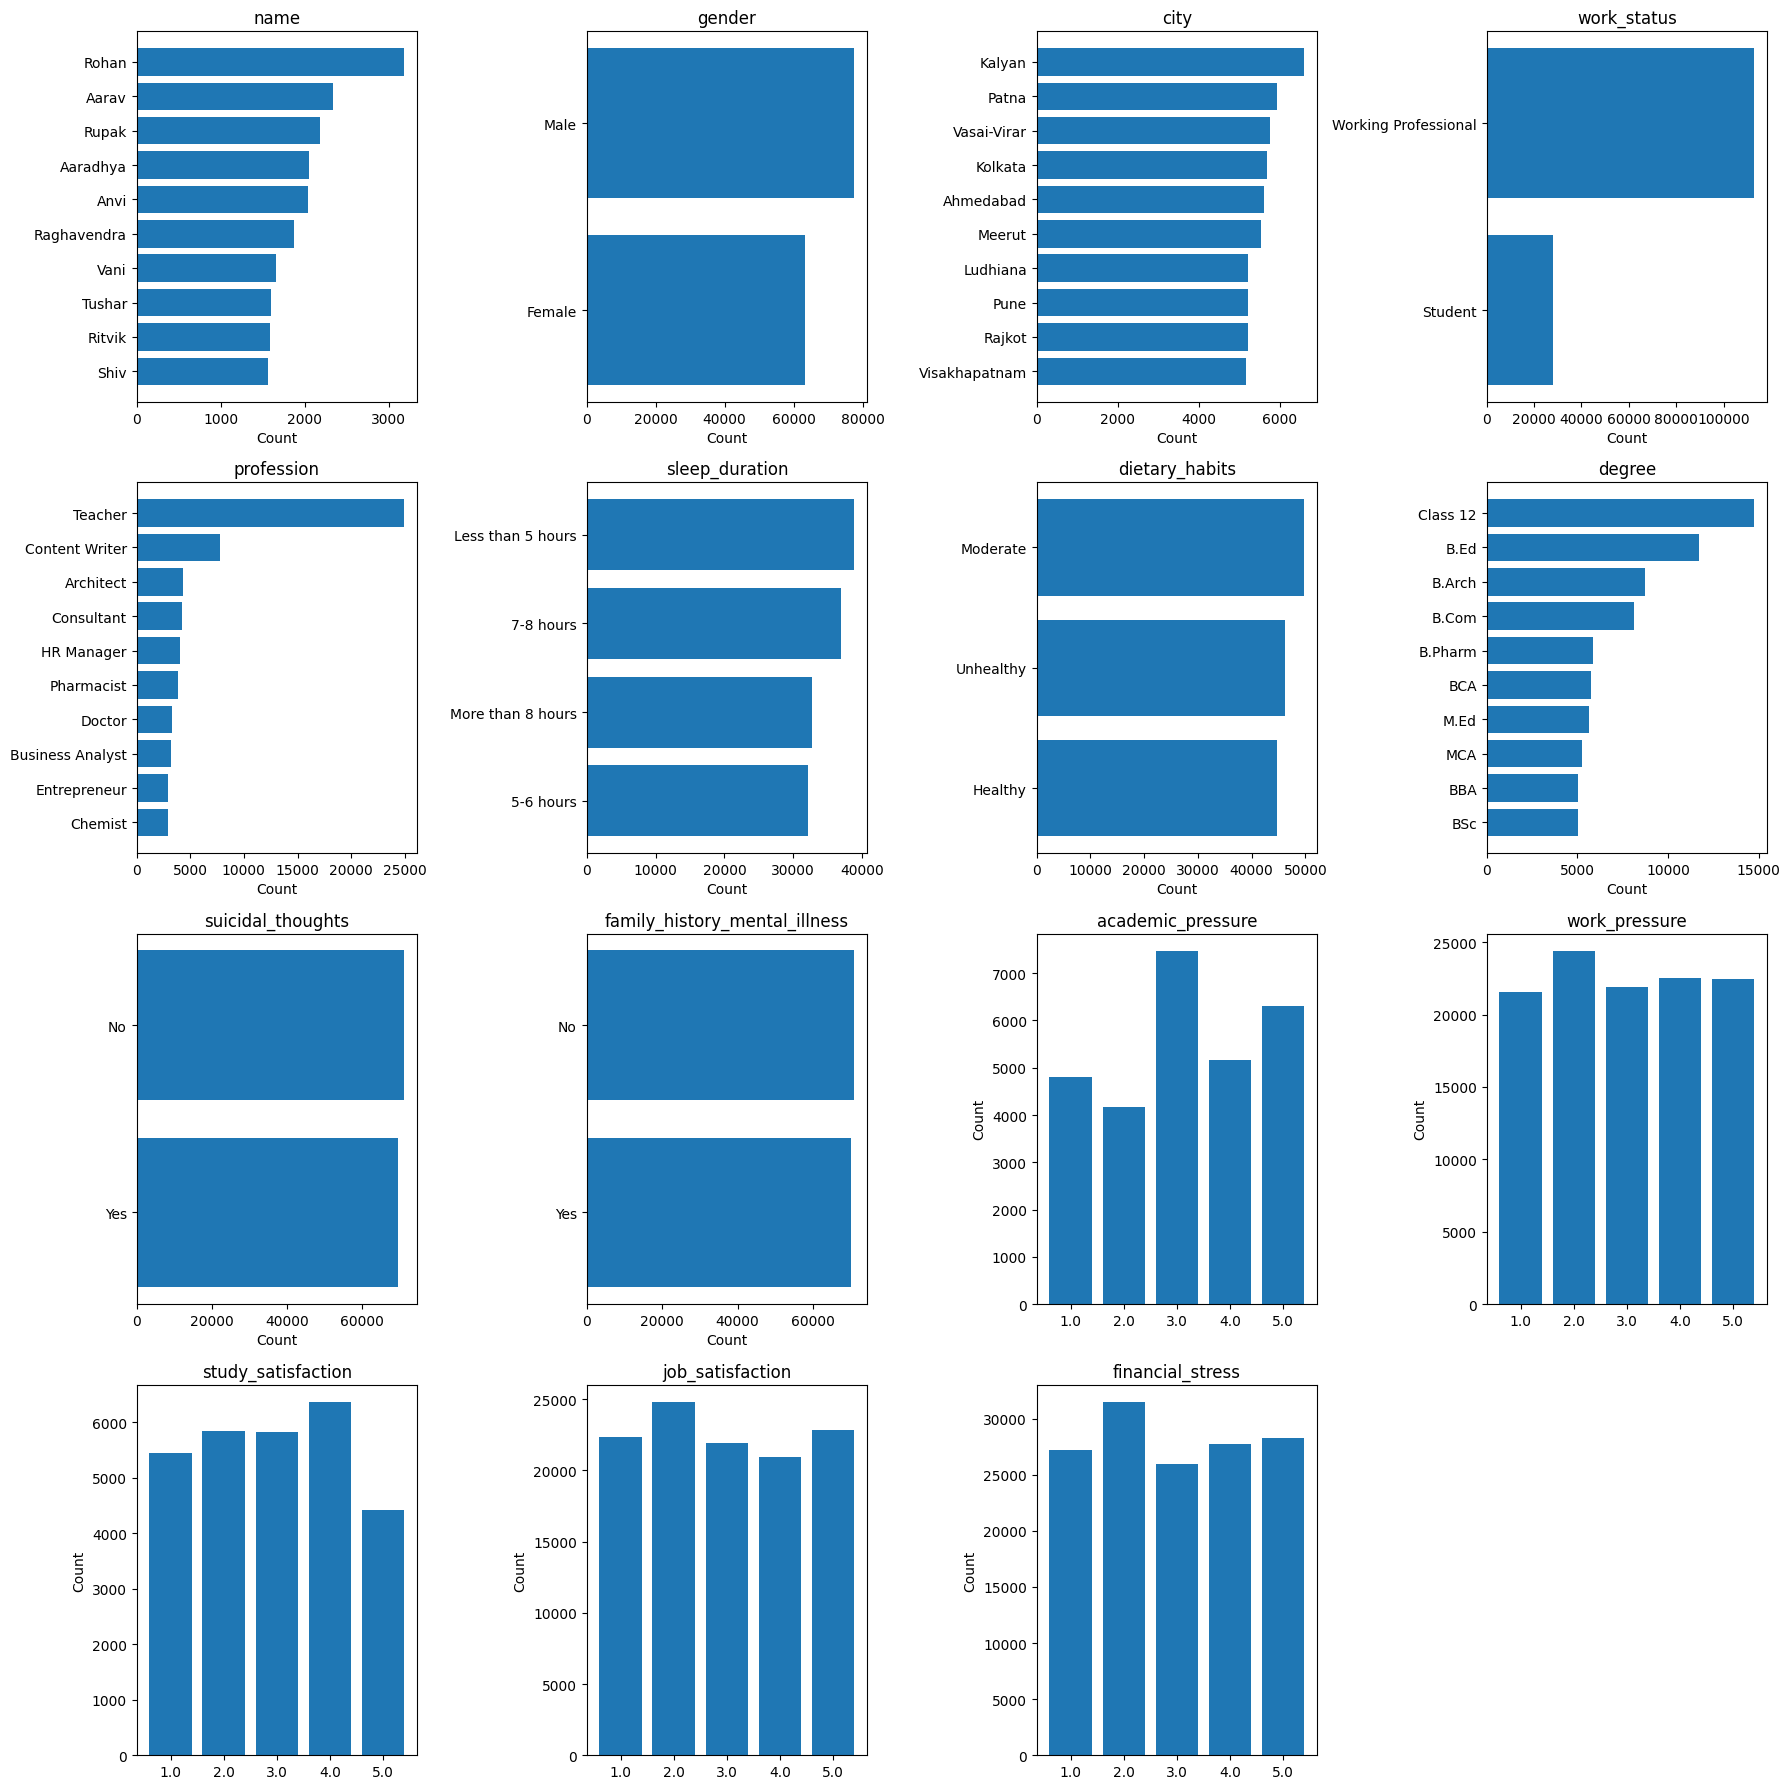

In [8]:

plot_columns = list(categorical_columns) + ordinal_columns

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(plot_columns):

    counts = train[col].value_counts(dropna=True)

    # Keep only the most frequent categories
    if col == "sleep_duration":
        counts = counts.head(4)

    elif col == "dietary_habits":
        counts = counts.head(3)

    elif len(counts) > 10:
        counts = counts.head(10)

    # Ordinal variables: 1 to 5
    if col in ordinal_columns:
        counts = counts.sort_index()

        axes[i].bar(
            counts.index.astype(str),
            counts.values
        )
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Count')

    else:
        counts = counts.sort_values()

        axes[i].barh(
            counts.index.astype(str),
            counts.values
        )
        axes[i].set_xlabel('Count')
        axes[i].set_ylabel('')

    axes[i].set_title(col)

for j in range(len(plot_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

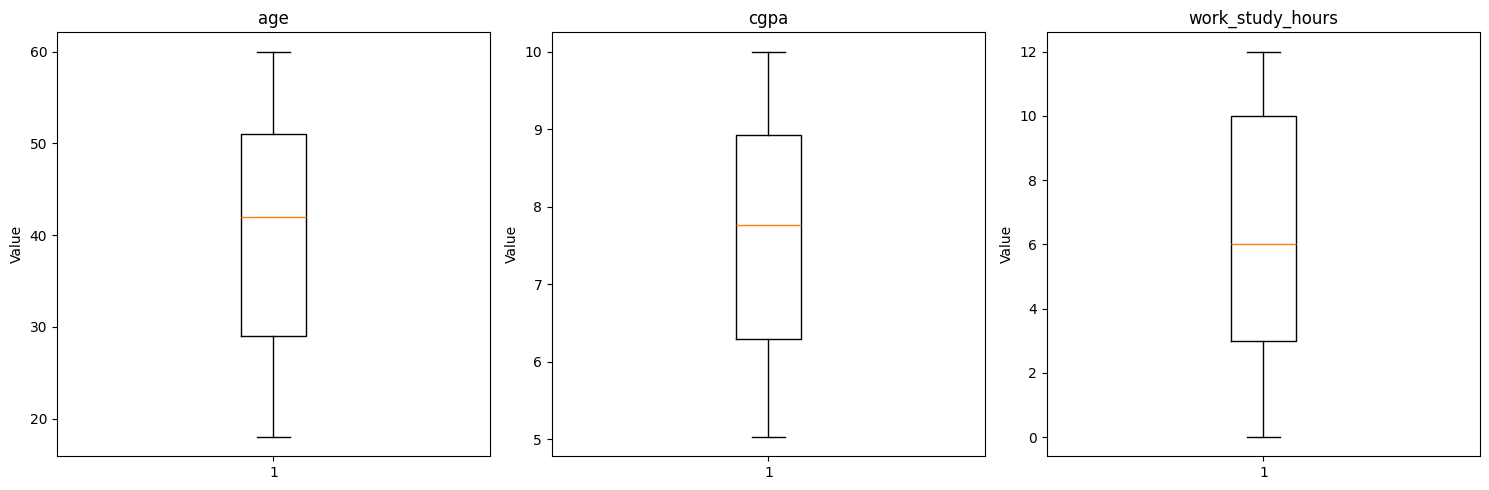

In [9]:
numeric_cols = [
    "age",
    "cgpa",
    "work_study_hours"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    ax.boxplot(train[col].dropna())
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

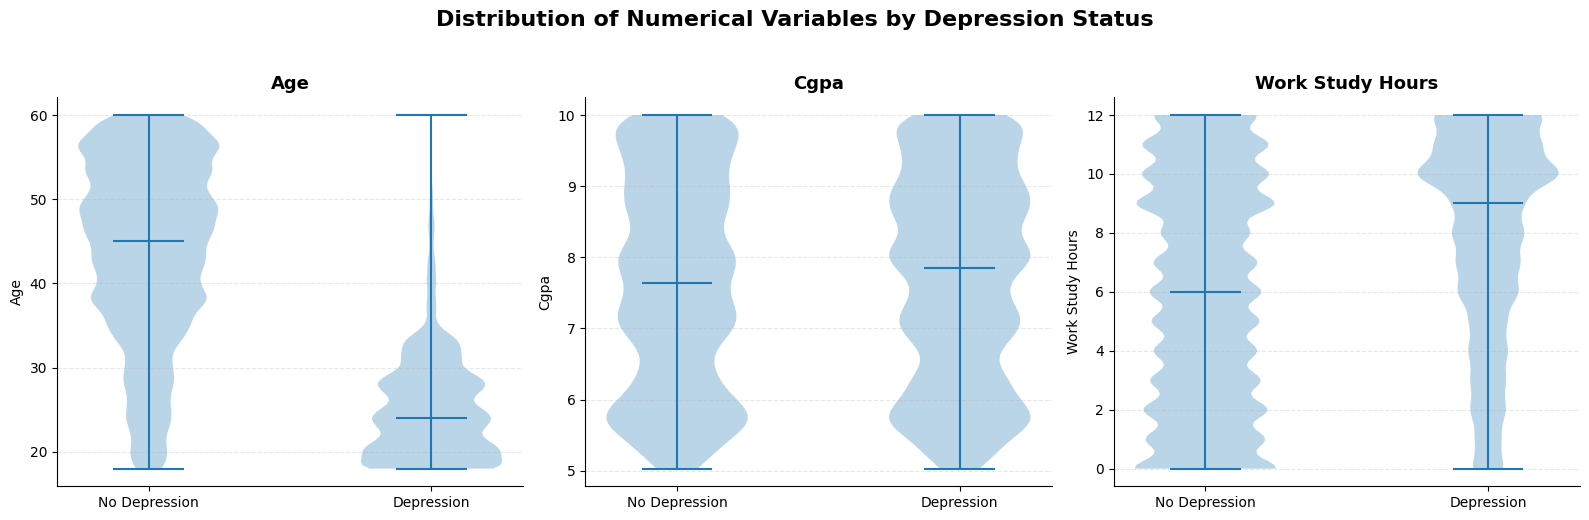

In [10]:
violin_columns = [
    "age",
    "cgpa",
    "work_study_hours"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, violin_columns):

    data = [
        train.loc[train["depression"] == 0, col].dropna(),
        train.loc[train["depression"] == 1, col].dropna()
    ]

    parts = ax.violinplot(
        data,
        showmeans=False,
        showmedians=True,
        showextrema=True
    )

    ax.set_title(
        col.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        ["No Depression", "Depression"],
        fontsize=10
    )

    ax.set_ylabel(
        col.replace("_", " ").title(),
        fontsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Distribution of Numerical Variables by Depression Status",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

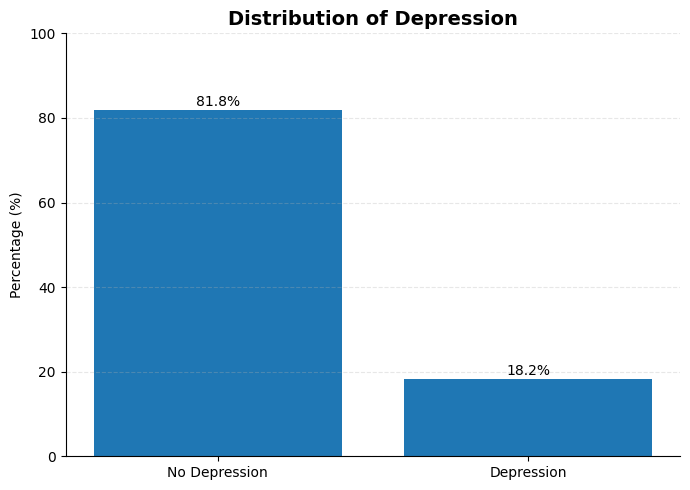

In [11]:
depression_percent = (
    train["depression"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Depression", "Depression"],
    depression_percent.values
)

ax.set_title(
    "Distribution of Depression",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, value in zip(bars, depression_percent.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

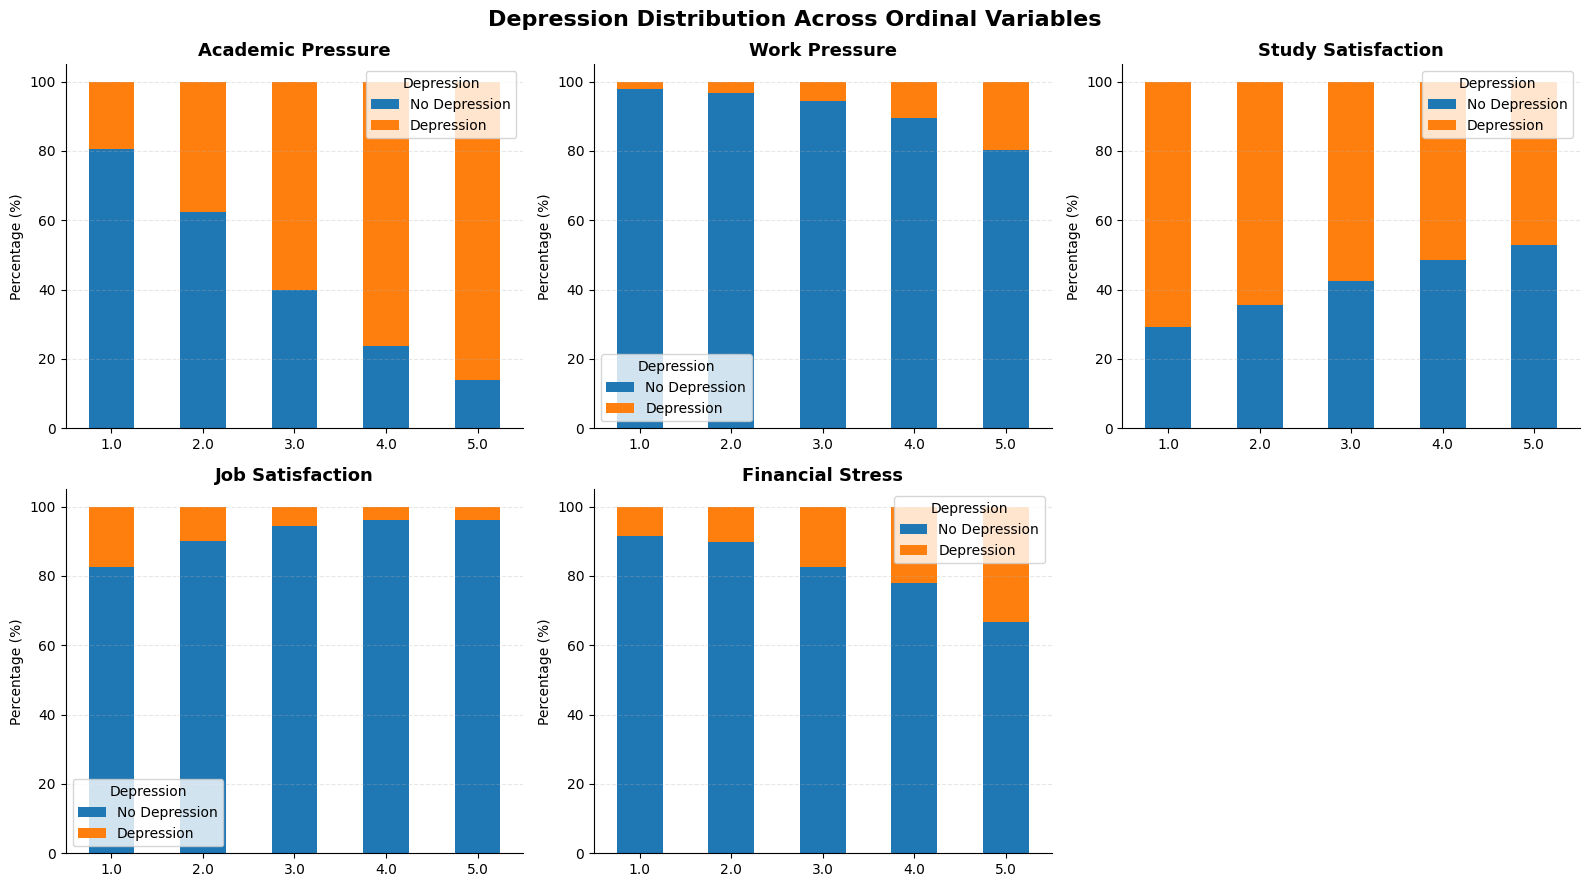

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, ordinal_columns):

    table = pd.crosstab(
        train[col],
        train["depression"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=[0, 1],
        fill_value=0
    )

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Percentage (%)")

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0
    )

    ax.legend(
        ["No Depression", "Depression"],
        title="Depression"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in axes[len(ordinal_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Depression Distribution Across Ordinal Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

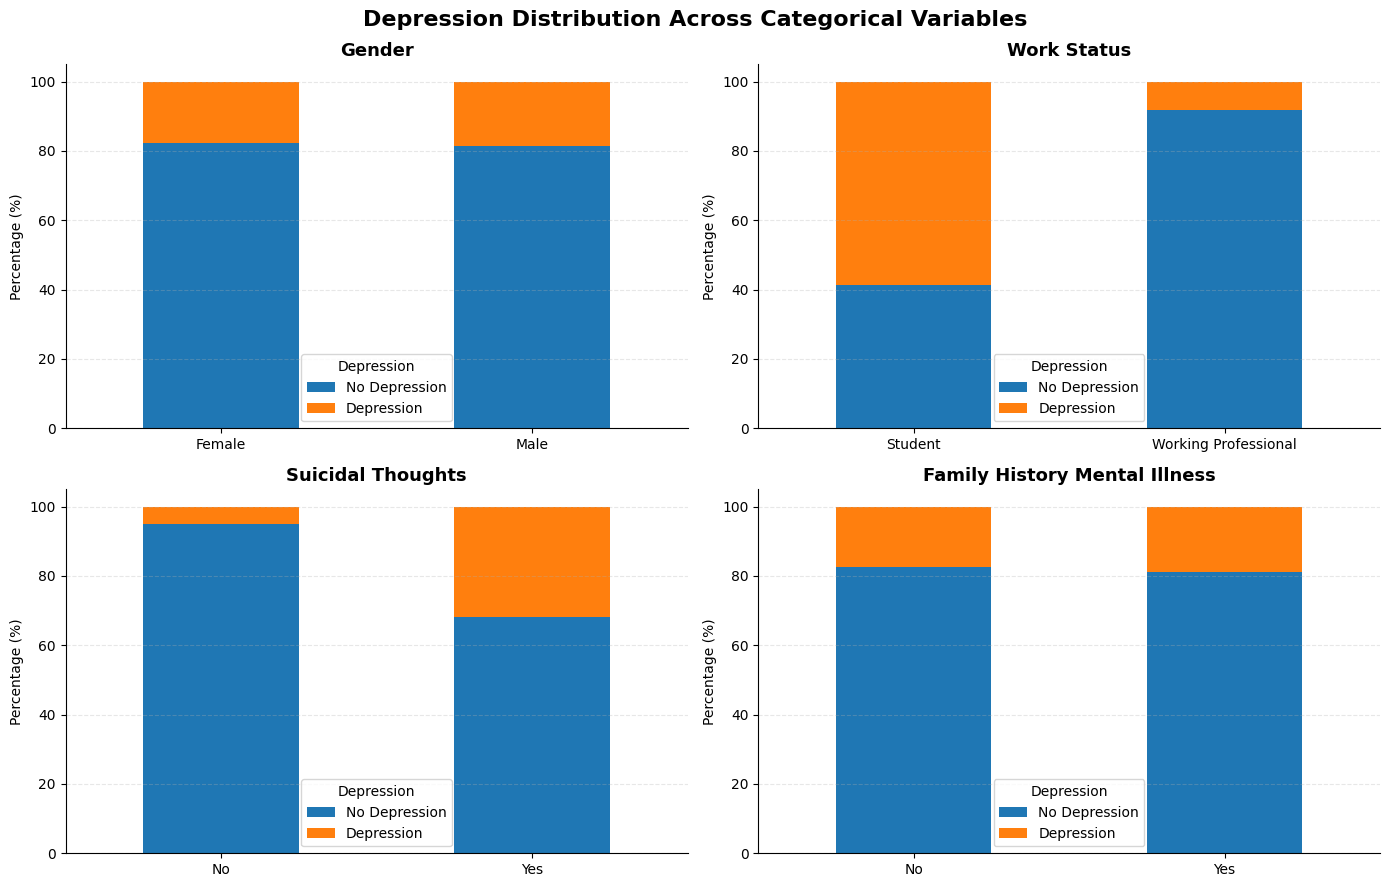

In [13]:
categorical_stack_columns = [
    "gender",
    "work_status",
    "suicidal_thoughts",
    "family_history_mental_illness"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_stack_columns):

    table = pd.crosstab(
        train[col],
        train["depression"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=[0, 1],
        fill_value=0
    )

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Percentage (%)")

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0
    )

    ax.legend(
        ["No Depression", "Depression"],
        title="Depression"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Depression Distribution Across Categorical Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [14]:
train.drop(columns=["id"]).corr(numeric_only=True)

,age,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,work_study_hours,financial_stress,depression
age,1.000000,-0.075956,-0.098924,0.005129,0.008862,0.030793,-0.118356,-0.083589,-0.564671
academic_pressure,-0.075956,1.000000,NaN,-0.025195,-0.112228,-1.000000,0.095650,0.152105,0.475037
work_pressure,-0.098924,NaN,1.000000,NaN,NaN,-0.036958,-0.002808,0.024412,0.216634
cgpa,0.005129,-0.025195,NaN,1.000000,-0.047078,1.000000,0.002875,0.006398,0.021729
study_satisfaction,0.008862,-0.112228,NaN,-0.047078,1.000000,-1.000000,-0.036934,-0.065001,-0.168014
job_satisfaction,0.030793,-1.000000,-0.036958,1.000000,-1.000000,1.000000,-0.029227,-0.029160,-0.168543
work_study_hours,-0.118356,0.095650,-0.002808,0.002875,-0.036934,-0.029227,1.000000,0.036134,0.191746
financial_stress,-0.083589,0.152105,0.024412,0.006398,-0.065001,-0.029160,0.036134,1.000000,0.227237
depression,-0.564671,0.475037,0.216634,0.021729,-0.168014,-0.168543,0.191746,0.227237,1.000000


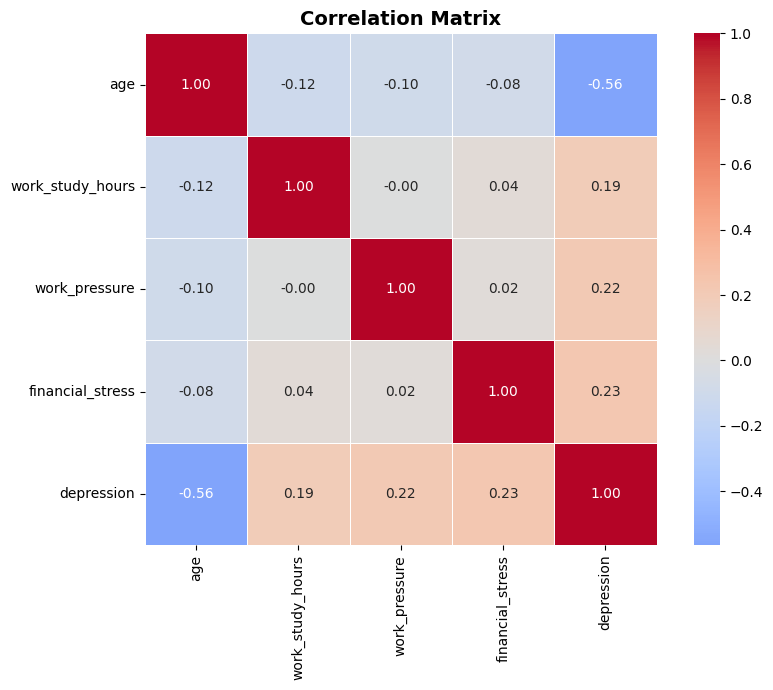

In [15]:
correlation_columns = [
    "age",
    "work_study_hours",
    "work_pressure",
    "financial_stress",
    "depression"
]

corr = train[correlation_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Data Preparation

#### Outliers

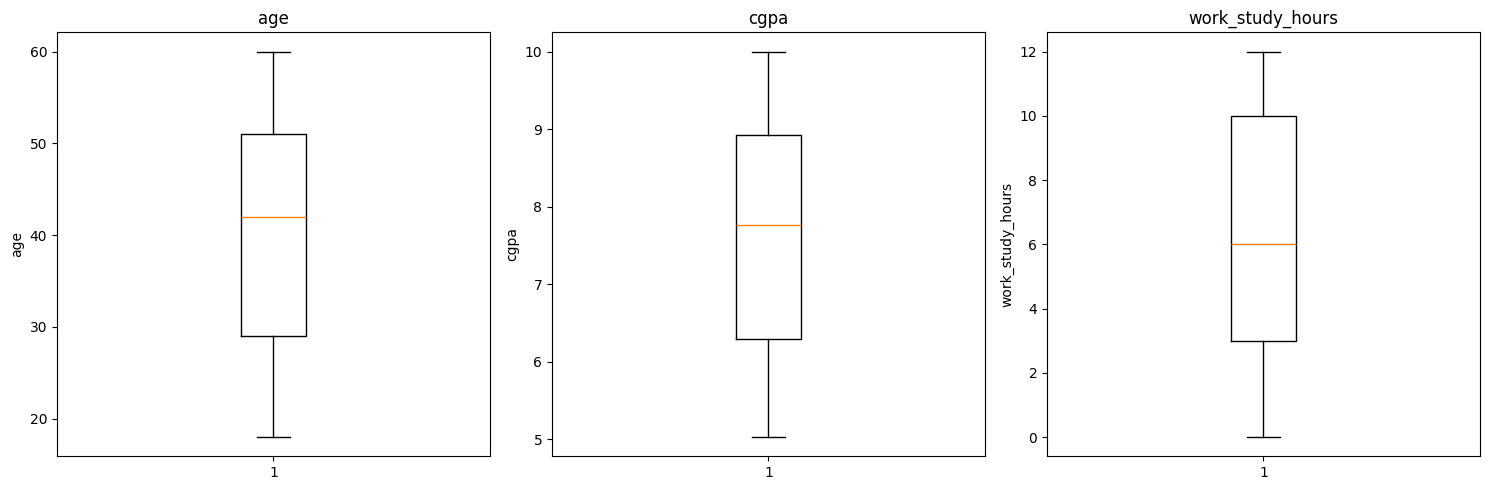

In [16]:
numeric_cols = [
    "age",
    "cgpa",
    "work_study_hours"
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    ax.boxplot(train[col].dropna())
    ax.set_title(col)
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# No outlier

In [17]:
for col in ordinal_columns:
    values = sorted(train[col].dropna().astype(int).unique().tolist())
    print(f"{col}: {values}")

# No unusual number in ordinal variables 

academic_pressure: [1, 2, 3, 4, 5]
work_pressure: [1, 2, 3, 4, 5]
study_satisfaction: [1, 2, 3, 4, 5]
job_satisfaction: [1, 2, 3, 4, 5]
financial_stress: [1, 2, 3, 4, 5]


#### Missing values

<Axes: >

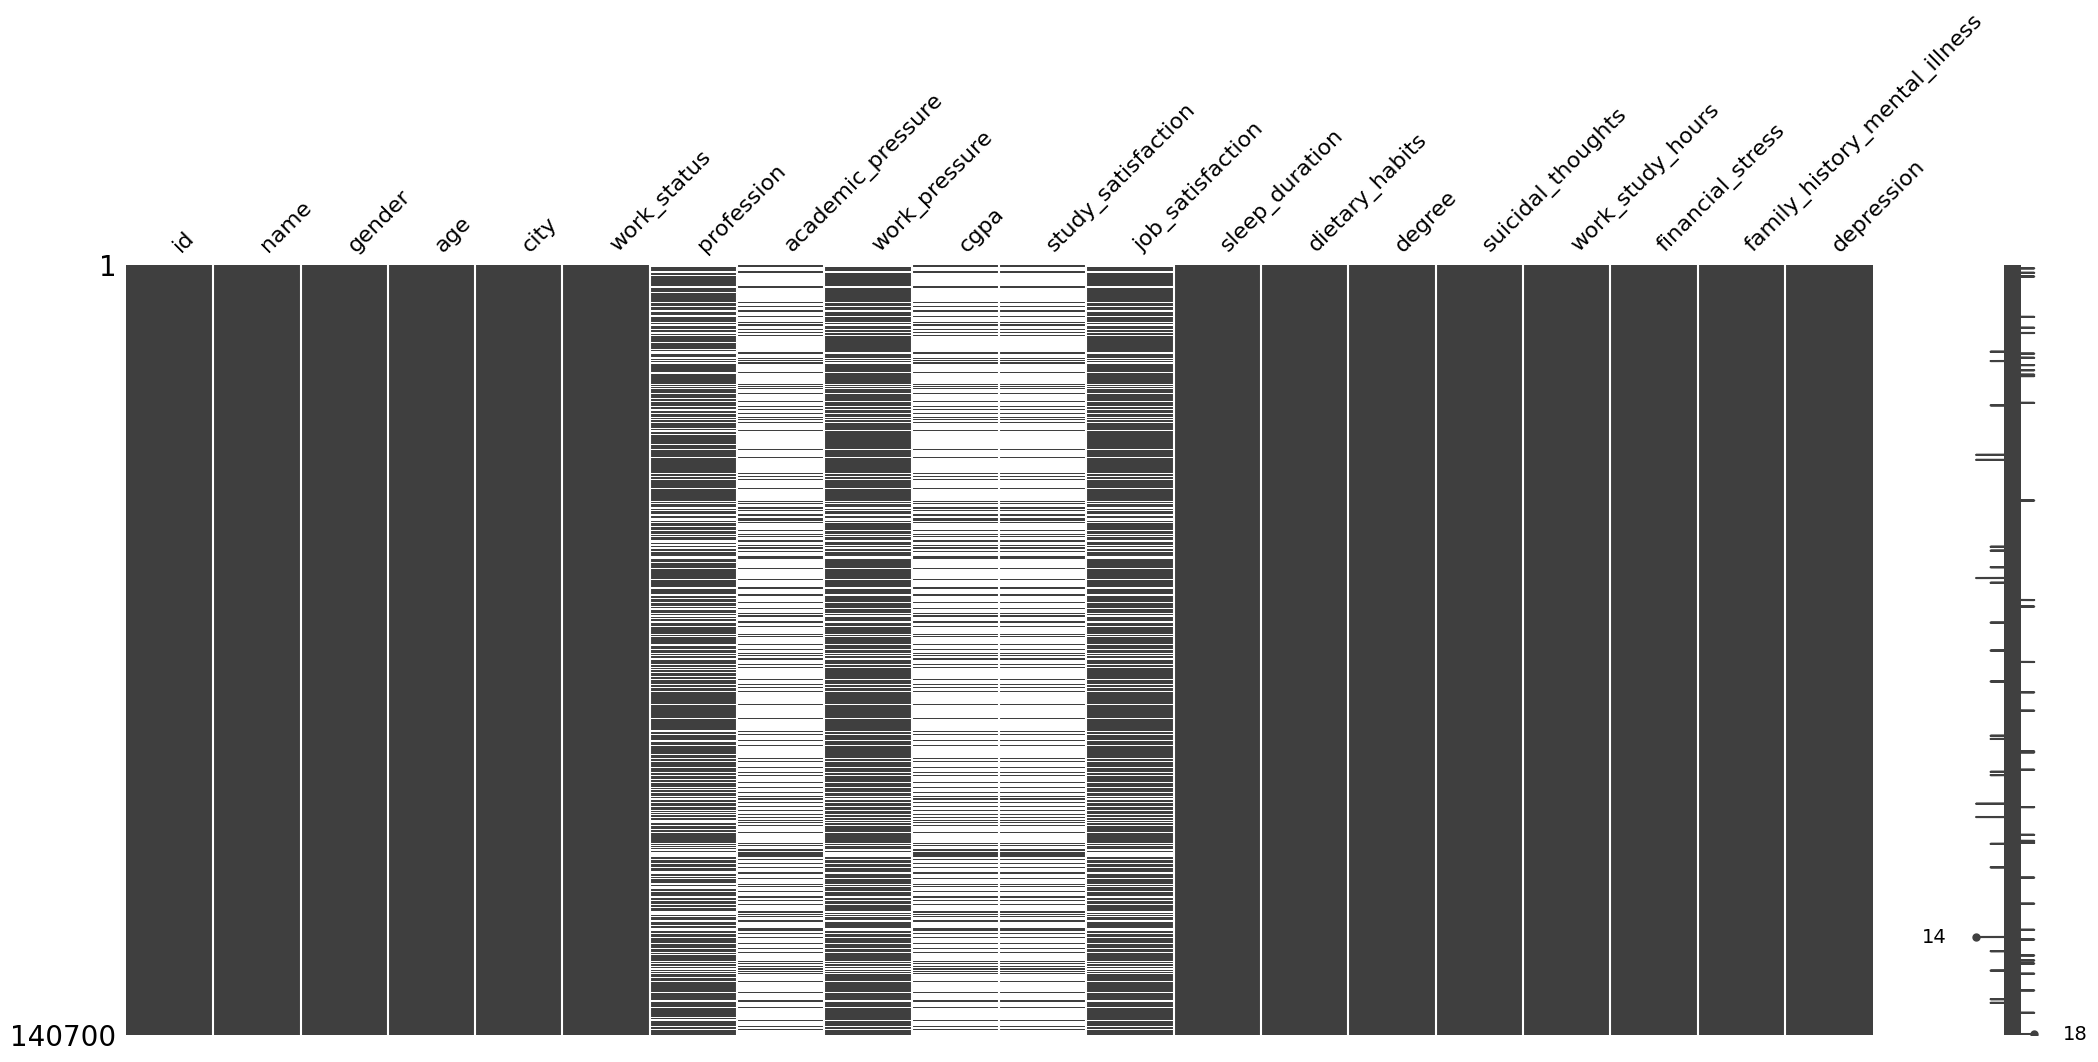

In [18]:
msno.matrix (train)

<Axes: >

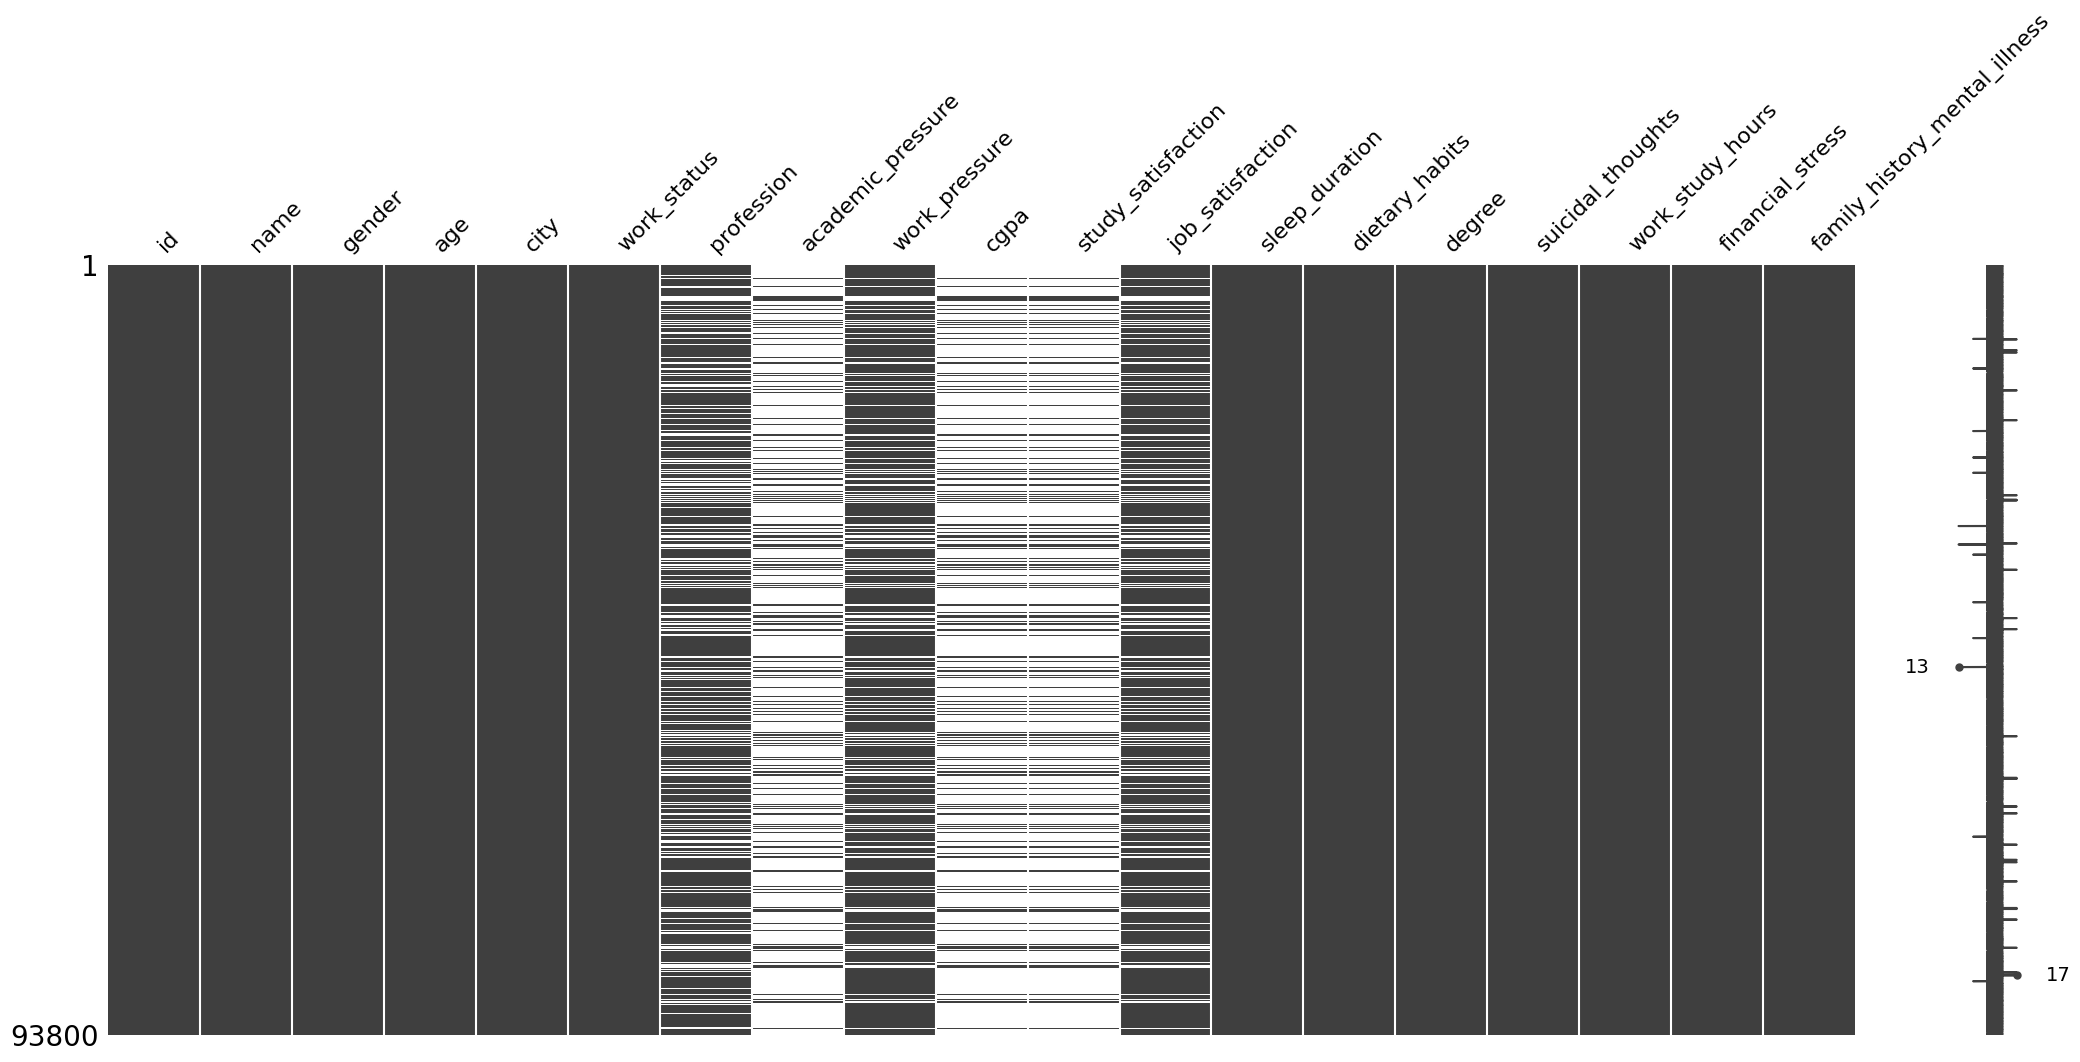

In [19]:
import missingno as msno
msno.matrix (test)

In [20]:
train_missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})

train_missing = train_missing.sort_values("missing_count", ascending=False)

train_missing

,missing_count,missing_percent
study_satisfaction,112803,80.172708
academic_pressure,112803,80.172708
cgpa,112802,80.171997
profession,36630,26.034115
work_pressure,27918,19.842217
job_satisfaction,27910,19.836532
financial_stress,4,0.002843
dietary_habits,4,0.002843
degree,2,0.001421
gender,0,0.000000


In [21]:
test_missing = pd.DataFrame({
    "missing_count": test.isna().sum(),
    "missing_percent": test.isna().mean() * 100
})

test_missing = test_missing.sort_values("missing_count", ascending=False)

test_missing

,missing_count,missing_percent
cgpa,75034,79.993603
academic_pressure,75033,79.992537
study_satisfaction,75033,79.992537
profession,24632,26.260128
work_pressure,18778,20.019190
job_satisfaction,18774,20.014925
dietary_habits,5,0.005330
degree,2,0.002132
gender,0,0.000000
id,0,0.000000


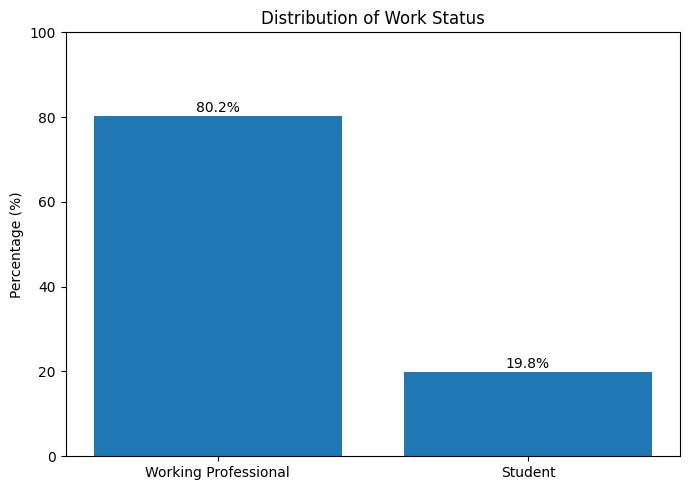

In [22]:
plt.figure(figsize=(7, 5))

counts = train["work_status"].value_counts()
percentages = counts / counts.sum() * 100

bars = plt.bar(
    percentages.index,
    percentages.values
)

plt.ylabel("Percentage (%)")
plt.xlabel("")
plt.title("Distribution of Work Status")

for bar, percentage in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.1f}%",
        ha="center"
    )

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [23]:
# To recognize the pattern of missing values
pd.crosstab(
    train["work_status"],
    train["cgpa"].notna()
)

cgpa,False,True
work_status,,
Student,9,27892
Working Professional,112793,6


In [24]:
pd.crosstab(
    train["work_status"],
    train["job_satisfaction"].notna()
)

job_satisfaction,False,True
work_status,,
Student,27893,8
Working Professional,17,112782


In [25]:
pd.crosstab(
    train["work_status"],
    train["study_satisfaction"].notna()
)

study_satisfaction,False,True
work_status,,
Student,10,27891
Working Professional,112793,6


In [26]:
pd.crosstab(
    train["work_status"],
    train["profession"].notna()
)

profession,False,True
work_status,,
Student,27867,34
Working Professional,8763,104036


In [27]:
pd.crosstab(
    train["work_status"],
    train["work_pressure"].notna()
)

work_pressure,False,True
work_status,,
Student,27898,3
Working Professional,20,112779


In [28]:
train[
    ["work_status", "cgpa", "job_satisfaction"]
].dropna()

,work_status,cgpa,job_satisfaction
1428,Student,9.63,3.0
116703,Student,9.44,2.0


In [29]:
random_missing = [
    "profession",
    "dietary_habits",
    "degree"
]

structural_missing = [
    "cgpa",
    "academic_pressure",
    "study_satisfaction",
    "work_pressure",
    "job_satisfaction"
]

no_missing = [
    "gender",
    "city",
    "age",
    "work_status",
    "sleep_duration",
    "suicidal_thoughts",
    "work_study_hours",
    "financial_stress",
    "family_history_mental_illness"
]

print("Random Missing Values:")
print(random_missing)

print("\nStructural Missing Values:")
print(structural_missing)

print("\nVariables with No Missing Values:")
print(no_missing)

Random Missing Values:
['profession', 'dietary_habits', 'degree']

Structural Missing Values:
['cgpa', 'academic_pressure', 'study_satisfaction', 'work_pressure', 'job_satisfaction']

Variables with No Missing Values:
['gender', 'city', 'age', 'work_status', 'sleep_duration', 'suicidal_thoughts', 'work_study_hours', 'financial_stress', 'family_history_mental_illness']


In [30]:
# Train / Validation Split

X = train.drop(columns=["depression"]).copy()
y = train["depression"].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=607
)

X_test = test.drop(columns=["id"]).copy()

In [31]:
# 1. Structural Missing - CGPA

student_mask_train = X_train["work_status"] == "Student"
student_mask_valid = X_valid["work_status"] == "Student"
student_mask_test = X_test["work_status"] == "Student"


# Median learned ONLY from training students
student_cgpa_median = X_train.loc[
    student_mask_train & X_train["cgpa"].notna(),
    "cgpa"
].median()


# Fill ONLY missing CGPA values among students
X_train.loc[
    student_mask_train & X_train["cgpa"].isna(),
    "cgpa"
] = student_cgpa_median

X_valid.loc[
    student_mask_valid & X_valid["cgpa"].isna(),
    "cgpa"
] = student_cgpa_median

X_test.loc[
    student_mask_test & X_test["cgpa"].isna(),
    "cgpa"
] = student_cgpa_median


print("Student CGPA median:", student_cgpa_median)

print(
    "Train student missing:",
    X_train.loc[student_mask_train, "cgpa"].isna().sum()
)

print(
    "Validation student missing:",
    X_valid.loc[student_mask_valid, "cgpa"].isna().sum()
)

print(
    "Test student missing:",
    X_test.loc[student_mask_test, "cgpa"].isna().sum()
)

Student CGPA median: 7.77
Train student missing: 0
Validation student missing: 0
Test student missing: 0


In [32]:
# 2. Structural + Random Missing - Ordinal Variables

student_mask_train = X_train["work_status"] == "Student"
student_mask_valid = X_valid["work_status"] == "Student"
student_mask_test = X_test["work_status"] == "Student"

worker_mask_train = X_train["work_status"] == "Working Professional"
worker_mask_valid = X_valid["work_status"] == "Working Professional"
worker_mask_test = X_test["work_status"] == "Working Professional"


# Student-specific variables

student_academic = X_train.loc[
    student_mask_train,
    "academic_pressure"
].dropna()

student_study = X_train.loc[
    student_mask_train,
    "study_satisfaction"
].dropna()


# Working Professional-specific variables

worker_work = X_train.loc[
    worker_mask_train,
    "work_pressure"
].dropna()

worker_job = X_train.loc[
    worker_mask_train,
    "job_satisfaction"
].dropna()


# Learn modes ONLY from TRAINING DATA

academic_pressure_mode = student_academic.mode().iloc[0]

study_satisfaction_mode = student_study.mode().iloc[0]

work_pressure_mode = worker_work.mode().iloc[0]

job_satisfaction_mode = worker_job.mode().iloc[0]


# Fill missing values only for applicable groups

# Academic Pressure → Students

X_train.loc[
    student_mask_train & X_train["academic_pressure"].isna(),
    "academic_pressure"
] = academic_pressure_mode

X_valid.loc[
    student_mask_valid & X_valid["academic_pressure"].isna(),
    "academic_pressure"
] = academic_pressure_mode

X_test.loc[
    student_mask_test & X_test["academic_pressure"].isna(),
    "academic_pressure"
] = academic_pressure_mode


# Study Satisfaction → Students

X_train.loc[
    student_mask_train & X_train["study_satisfaction"].isna(),
    "study_satisfaction"
] = study_satisfaction_mode

X_valid.loc[
    student_mask_valid & X_valid["study_satisfaction"].isna(),
    "study_satisfaction"
] = study_satisfaction_mode

X_test.loc[
    student_mask_test & X_test["study_satisfaction"].isna(),
    "study_satisfaction"
] = study_satisfaction_mode


# Work Pressure → Working Professionals

X_train.loc[
    worker_mask_train & X_train["work_pressure"].isna(),
    "work_pressure"
] = work_pressure_mode

X_valid.loc[
    worker_mask_valid & X_valid["work_pressure"].isna(),
    "work_pressure"
] = work_pressure_mode

X_test.loc[
    worker_mask_test & X_test["work_pressure"].isna(),
    "work_pressure"
] = work_pressure_mode


# Job Satisfaction → Working Professionals

X_train.loc[
    worker_mask_train & X_train["job_satisfaction"].isna(),
    "job_satisfaction"
] = job_satisfaction_mode

X_valid.loc[
    worker_mask_valid & X_valid["job_satisfaction"].isna(),
    "job_satisfaction"
] = job_satisfaction_mode

X_test.loc[
    worker_mask_test & X_test["job_satisfaction"].isna(),
    "job_satisfaction"
] = job_satisfaction_mode


# Not Applicable → NaN

# Students do not have work-related variables

X_train.loc[
    student_mask_train,
    ["work_pressure", "job_satisfaction"]
] = np.nan

X_valid.loc[
    student_mask_valid,
    ["work_pressure", "job_satisfaction"]
] = np.nan

X_test.loc[
    student_mask_test,
    ["work_pressure", "job_satisfaction"]
] = np.nan


# Working Professionals do not have study-related variables

X_train.loc[
    worker_mask_train,
    ["academic_pressure", "study_satisfaction"]
] = np.nan

X_valid.loc[
    worker_mask_valid,
    ["academic_pressure", "study_satisfaction"]
] = np.nan

X_test.loc[
    worker_mask_test,
    ["academic_pressure", "study_satisfaction"]
] = np.nan


print("Academic Pressure mode:", academic_pressure_mode)
print("Study Satisfaction mode:", study_satisfaction_mode)
print("Work Pressure mode:", work_pressure_mode)
print("Job Satisfaction mode:", job_satisfaction_mode)

Academic Pressure mode: 3.0
Study Satisfaction mode: 4.0
Work Pressure mode: 2.0
Job Satisfaction mode: 2.0


In [33]:

# 3. Random Missing - Categorical Variables


random_categorical = [
    "profession",
    "dietary_habits",
    "degree"
]

for col in random_categorical:

    X_train[col] = X_train[col].fillna("nan")

    X_valid[col] = X_valid[col].fillna("nan")

    X_test[col] = X_test[col].fillna("nan")


print("Train missing:")
print(X_train[random_categorical].isna().sum())

print("\nValidation missing:")
print(X_valid[random_categorical].isna().sum())

print("\nTest missing:")
print(X_test[random_categorical].isna().sum())

Train missing:
profession        0
dietary_habits    0
degree            0
dtype: int64

Validation missing:
profession        0
dietary_habits    0
degree            0
dtype: int64

Test missing:
profession        0
dietary_habits    0
degree            0
dtype: int64


In [34]:
# 4. Random Missing - Financial Stress


financial_stress_median = X_train[
    "financial_stress"
].median()


X_train["financial_stress"] = X_train[
    "financial_stress"
].fillna(financial_stress_median)

X_valid["financial_stress"] = X_valid[
    "financial_stress"
].fillna(financial_stress_median)

X_test["financial_stress"] = X_test[
    "financial_stress"
].fillna(financial_stress_median)


print(
    "Financial Stress median:",
    financial_stress_median
)

Financial Stress median: 3.0


In [35]:
# 5. Check Missing Values

print("========== TRAIN ==========")
print(
    X_train.isna().sum()[
        X_train.isna().sum() > 0
    ]
)

print("\n========== VALIDATION ==========")
print(
    X_valid.isna().sum()[
        X_valid.isna().sum() > 0
    ]
)

print("\n========== TEST ==========")
print(
    X_test.isna().sum()[
        X_test.isna().sum() > 0
    ]
)

========== TRAIN ==========
academic_pressure     90242
work_pressure         22318
cgpa                  90237
study_satisfaction    90242
job_satisfaction      22318
dtype: int64

========== VALIDATION ==========
academic_pressure     22557
work_pressure          5583
cgpa                  22556
study_satisfaction    22557
job_satisfaction       5583
dtype: int64

========== TEST ==========
academic_pressure     75028
work_pressure         18772
cgpa                  75025
study_satisfaction    75028
job_satisfaction      18772
dtype: int64


#### Encoding

In [36]:
# Binary Variables - Ordinal Encoding

binary_columns = [
    "gender",
    "suicidal_thoughts",
    "work_status",
    "family_history_mental_illness"
]

ordinal_enc = preprocessing.OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# ------------------------------------------------------------
# Fit ONLY on training data
# ------------------------------------------------------------

X_train[binary_columns] = ordinal_enc.fit_transform(
    X_train[binary_columns]
)

# Transform validation and test using the SAME encoder

X_valid[binary_columns] = ordinal_enc.transform(
    X_valid[binary_columns]
)

X_test[binary_columns] = ordinal_enc.transform(
    X_test[binary_columns]
)

# Convert to float explicitly

X_train[binary_columns] = X_train[binary_columns].astype(float)
X_valid[binary_columns] = X_valid[binary_columns].astype(float)
X_test[binary_columns] = X_test[binary_columns].astype(float)

# Check encoding


print("========== BINARY ENCODING CHECK ==========")

for col in binary_columns:
    print(f"\n{col}")
    print("TRAIN:")
    print(sorted(X_train[col].unique()))

    print("VALIDATION:")
    print(sorted(X_valid[col].unique()))

    print("TEST:")
    print(sorted(X_test[col].unique()))

# Check for non-numeric binary columns

print("\n========== NON-NUMERIC CHECK ==========")

print("Train:",
      X_train[binary_columns].select_dtypes(
          exclude=np.number
      ).columns.tolist())

print("Validation:",
      X_valid[binary_columns].select_dtypes(
          exclude=np.number
      ).columns.tolist())

print("Test:",
      X_test[binary_columns].select_dtypes(
          exclude=np.number
      ).columns.tolist())

========== BINARY ENCODING CHECK ==========

gender
TRAIN:
[np.float64(0.0), np.float64(1.0)]
VALIDATION:
[np.float64(0.0), np.float64(1.0)]
TEST:
[np.float64(0.0), np.float64(1.0)]

suicidal_thoughts
TRAIN:
[np.float64(0.0), np.float64(1.0)]
VALIDATION:
[np.float64(0.0), np.float64(1.0)]
TEST:
[np.float64(0.0), np.float64(1.0)]

work_status
TRAIN:
[np.float64(0.0), np.float64(1.0)]
VALIDATION:
[np.float64(0.0), np.float64(1.0)]
TEST:
[np.float64(0.0), np.float64(1.0)]

family_history_mental_illness
TRAIN:
[np.float64(0.0), np.float64(1.0)]
VALIDATION:
[np.float64(0.0), np.float64(1.0)]
TEST:
[np.float64(0.0), np.float64(1.0)]

========== NON-NUMERIC CHECK ==========
Train: []
Validation: []
Test: []


In [37]:
# Feature Engineering - City Cleaning

# 1. Clean invalid and inconsistent city values

city_cleaning = {
    "3.0": "nan",
    "M.Com": "nan",
    "M.Tech": "nan",
    "MCA": "nan",
    "ME": "nan",
    "MSc": "nan",
    "No": "nan",
    "Researcher": "nan",
    "Less Delhi": "Delhi",
    "Less than 5 Kalyan": "Kalyan"
}

for df in [X_train, X_valid, X_test]:
    df["city"] = df["city"].replace(city_cleaning)


# 2. Fix obvious city typos

city_typos = {
   "Molkata": "Kolkata",
    "Tolkata": "Kolkata",
    "Khaziabad": "Ghaziabad",
    "Nalyan": "Kalyan"
}

for df in [X_train, X_valid, X_test]:
    df["city"] = df["city"].replace(city_typos)


# 3. Replace confirmed name-like city values with "nan"

city_like_names = [
    'Vidhi', 'Krishna', 'Aishwarya', 'Aditya', 'Raghavendra',
    'Mira', 'Anvi', 'Ayansh', 'Shrey', 'Ivaan', 'Vaanya',
    'Gaurav', 'Harsh', 'Reyansh', 'Kashish', 'Vaishnavi',
    'Chhavi', 'Parth', 'Tushar', 'Rashi', 'Armaan', 'Dhruv',
    'Aaradhya', 'Pooja', 'Khushi', 'Jhanvi'
]

for df in [X_train, X_valid, X_test]:
    df["city"] = df["city"].replace(city_like_names, "nan")


# 4. Group rare cities into "Other"
# IMPORTANT: learn rare cities ONLY from X_train

city_counts = X_train["city"].value_counts()

rare_cities = city_counts[city_counts < 100].index

for df in [X_train, X_valid, X_test]:
    df["city"] = df["city"].replace(rare_cities, "Other")


# Check
print("TRAIN city categories:")
print(X_train["city"].value_counts(dropna=False).to_string())

print("\nVALIDATION city categories:")
print(X_valid["city"].value_counts(dropna=False).to_string())

print("\nTEST city categories:")
print(X_test["city"].value_counts(dropna=False).to_string())

TRAIN city categories:
city
Kalyan           5260
Patna            4747
Vasai-Virar      4649
Ahmedabad        4499
Kolkata          4492
Meerut           4371
Pune             4189
Rajkot           4160
Ludhiana         4134
Visakhapatnam    4129
Srinagar         4090
Mumbai           3986
Indore           3926
Agra             3779
Surat            3717
Varanasi         3644
Hyderabad        3629
Vadodara         3617
Kanpur           3531
Thane            3472
Jaipur           3453
Lucknow          3420
Nagpur           3341
Bangalore        3266
Chennai          3221
Ghaziabad        2964
Delhi            2850
Bhopal           2804
Faridabad        2629
Nashik           2517
Other              74

VALIDATION city categories:
city
Kalyan           1333
Kolkata          1200
Patna            1177
Meerut           1157
Vasai-Virar      1116
Ahmedabad        1114
Ludhiana         1092
Rajkot           1047
Visakhapatnam    1047
Pune             1021
Srinagar          984
Mumbai        

In [38]:
# Apply TRAIN-derived profession categories

# Categories that are allowed based on X_train
allowed_professions = set(
    X_train["profession"].unique()
)

for df in [X_train, X_valid, X_test]:

    # Anything not seen in training becomes "Other"
    df["profession"] = df["profession"].where(
        df["profession"].isin(allowed_professions),
        "Other"
    )


# Check
print("========== PROFESSION CATEGORIES AFTER CLEANING ==========")

print("\nTRAIN:")
print(X_train["profession"].value_counts(dropna=False).to_string())

print("\nVALIDATION:")
print(X_valid["profession"].value_counts(dropna=False).to_string())

print("\nTEST:")
print(test["profession"].value_counts(dropna=False).to_string())

========== PROFESSION CATEGORIES AFTER CLEANING ==========

TRAIN:
profession
nan                       29269
Teacher                   19975
Content Writer             6258
Architect                  3519
Consultant                 3379
HR Manager                 3221
Pharmacist                 3111
Doctor                     2557
Business Analyst           2517
Entrepreneur               2389
Chemist                    2372
Chef                       2295
Educational Consultant     2293
Data Scientist             1929
Researcher                 1847
Lawyer                     1765
Customer Support           1666
Marketing Manager          1572
Pilot                      1555
Travel Consultant          1460
Sales Executive            1415
Manager                    1400
Plumber                    1398
Judge                      1342
Financial Analyst          1265
Electrician                1263
Civil Engineer             1195
UX/UI Designer             1180
Software Engineer         

In [39]:
# SLEEP DURATION — CLEANING & IMPUTATION

sleep_mapping = {
    "1-2 hours": 1.5,
    "1-3 hours": 2.0,
    "1-6 hours": 3.5,
    "2-3 hours": 2.5,
    "3-4 hours": 3.5,
    "3-6 hours": 4.5,
    "4-5 hours": 4.5,
    "4-6 hours": 5.0,
    "5-6 hours": 5.5,
    "6-7 hours": 6.5,
    "6-8 hours": 7.0,
    "7-8 hours": 7.5,
    "8-9 hours": 8.5,
    "9-11 hours": 10.0,
    "10-11 hours": 10.5,
    "Less than 5 hours": 4.5,
    "35-36 hours": 5.0,
    "40-45 hours": 5.5,
    "45-48 hours": 6.75,
    "49 hours": 7.0,
    "55-66 hours": 5.5,
    "45": 4.5,
    "8 hours": 8.0
}

invalid_values = [
    "No",
    "Sleep_Duration",
    "Unhealthy",
    "Moderate",
    "9-6 hours",
    "9-6",
    "10-6 hours",
    "than 5 hours",
    "Work_Study_Hours",
    "Indore",
    "Pune",
    "9-5",
    "9-5 hours"
]


# Apply cleaning to TRAIN / VALIDATION / TEST

for df in [X_train, X_valid, X_test]:

    df["sleep_duration"] = (
        df["sleep_duration"]
        .replace(sleep_mapping)
        .replace(invalid_values, np.nan)
    )

    df["sleep_duration"] = pd.to_numeric(
        df["sleep_duration"],
        errors="coerce"
    )


# Learn median ONLY from TRAIN

sleep_median = X_train["sleep_duration"].median()

print("Training sleep-duration median:", sleep_median)


# Impute TRAIN / VALIDATION / TEST
# using TRAINING median

X_train["sleep_duration"] = X_train[
    "sleep_duration"
].fillna(sleep_median)

X_valid["sleep_duration"] = X_valid[
    "sleep_duration"
].fillna(sleep_median)

X_test["sleep_duration"] = X_test[
    "sleep_duration"
].fillna(sleep_median)


# Check

print("\n========== MISSING VALUES ==========")

print("Train:",
      X_train["sleep_duration"].isna().sum())

print("Validation:",
      X_valid["sleep_duration"].isna().sum())

print("Test:",
      X_test["sleep_duration"].isna().sum())

print("\n========== DATA TYPES ==========")

print("Train:",
      X_train["sleep_duration"].dtype)

print("Validation:",
      X_valid["sleep_duration"].dtype)

print("Test:",
      X_test["sleep_duration"].dtype)

Training sleep-duration median: 5.5

========== MISSING VALUES ==========
Train: 0
Validation: 0
Test: 0

========== DATA TYPES ==========
Train: float64
Validation: float64
Test: float64


In [40]:
# DIETARY HABITS — CLEANING, IMPUTATION & ORDINAL ENCODING

dietary_cleaning = {
   "yes": "Healthy", "Yes": "Healthy", "More Healthy": "Healthy",
    "1": "Healthy", "1.0": "Healthy", 1: "Healthy", 1.0: "Healthy",

    "no": "Unhealthy", "No": "Unhealthy",
    "3": "Unhealthy", "3.0": "Unhealthy", 3: "Unhealthy", 3.0: "Unhealthy",
    "less than healthy": "Unhealthy", "Less than Healthy": "Unhealthy",
    "Hormonal": "Unhealthy", "No Healthy": "Unhealthy",
    "Less Healthy": "Unhealthy",

    "2": "Moderate", "2.0": "Moderate", 2: "Moderate", 2.0: "Moderate"
}

invalid_dietary = [
    "Pratham", "BSc", "Gender", "Mihir", "Electrician",
    "M.Tech", "Vegas", "Male", "Indoor", "Class 12"
]

valid_categories = ["Healthy", "Moderate", "Unhealthy"]


# 1. Apply known cleaning rules

for df in [X_train, X_valid, X_test]:

    df["dietary_habits"] = df["dietary_habits"].replace(
        dietary_cleaning
    )


# 2. Determine the mode ONLY from TRAINING data

valid_train = X_train["dietary_habits"].isin(valid_categories)

dietary_mode = X_train.loc[
    valid_train,
    "dietary_habits"
].mode()[0]

print("Training dietary mode:", dietary_mode)


# 3. Replace invalid / missing values
#    using TRAINING mode

for df in [X_train, X_valid, X_test]:

    invalid_mask = ~df["dietary_habits"].isin(
        valid_categories
    )

    df.loc[
        invalid_mask,
        "dietary_habits"
    ] = dietary_mode


# 4. Ordinal encoding

dietary_mapping = {
    "Healthy": 0,
    "Moderate": 1,
    "Unhealthy": 2
}

for df in [X_train, X_valid, X_test]:

    df["dietary_habits"] = df["dietary_habits"].map(
        dietary_mapping
    )


# 5. Check results

print("\n========== DIETARY HABITS ==========")

print("\nTRAIN:")
print(X_train["dietary_habits"].value_counts().sort_index())

print("\nVALIDATION:")
print(X_valid["dietary_habits"].value_counts().sort_index())

print("\nTEST:")
print(X_test["dietary_habits"].value_counts().sort_index())

print("\n========== MISSING VALUES ==========")

print("Train:",
      X_train["dietary_habits"].isna().sum())

print("Validation:",
      X_valid["dietary_habits"].isna().sum())

print("Test:",
      X_test["dietary_habits"].isna().sum())

Training dietary mode: Moderate

========== DIETARY HABITS ==========

TRAIN:
dietary_habits
0    35790
1    39793
2    36977
Name: count, dtype: int64

VALIDATION:
dietary_habits
0    8956
1    9927
2    9257
Name: count, dtype: int64

TEST:
dietary_habits
0    29969
1    33038
2    30793
Name: count, dtype: int64

========== MISSING VALUES ==========
Train: 0
Validation: 0
Test: 0


In [41]:
# DEGREE — CLEANING & RARE CATEGORY GROUPING

degree_cleaning = {
    "B.Sc": "BSc",
    "BEd": "B.Ed",
    "BPharm": "B.Pharm",
    "BArch": "B.Arch",
    "MEd": "M.Ed",
    "B": "BSc",
    "M": "MSc",
    "MPharm": "M.Pharm",
    "MTech": "M.Tech",
    "M_Tech": "M.Tech",
    "LLBA": "LLB",
    "LL.Com": "LLB",
    "LLCom": "LLB",
    "B.B.Arch": "B.Arch",
    "B B.Com": "B.Com",
    "B BA": "BBA",
    "BB": "BBA",
    "LLEd": "L.Ed",
}

obvious_invalid = [
    "UX/UI Designer", "Kalyan", "Nalini", "Bhopal", "Degree", "Jhanvi",
    "Veda", "Business Analyst", "Data Scientist", "Unite", "HR Manager",
    "Badhya", "Vrinda", "Bhavesh", "Vivaan",
    "Plumber", "Brit", "Ritik", "Brithika", "Pihu", "Aarav",
    "Entrepreneur", "Lata", "Marsh", "Navya", "Mahika", "Mthanya",
    "Working Professional", "Esha", "Mihir", "Advait"
]

obvious_numbers = [
    "20", "0", "29", "24", "5.61", "5.56", "7.06", "8.56",
    "5.88", "B.03", "B.3.79"
]


# 1. Apply cleaning rules to all datasets

for df in [X_train, X_valid, X_test]:

    df["degree"] = df["degree"].replace(degree_cleaning)

    df["degree"] = df["degree"].replace(
        obvious_invalid + obvious_numbers,
        "nan"
    )


# 2. Identify rare degrees using TRAINING data ONLY

min_count = 10

degree_counts = X_train["degree"].value_counts(
    dropna=False
)

rare_degrees = degree_counts[
    degree_counts < min_count
].index


# 3. Group rare categories into "Other"

for df in [X_train, X_valid, X_test]:

    df["degree"] = df["degree"].where(
        ~df["degree"].isin(rare_degrees),
        "Other"
    )


# 4. Check results

print("========== DEGREE ==========")

print("\nTRAIN:")
print(
    X_train["degree"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nVALIDATION:")
print(
    X_valid["degree"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nTEST:")
print(
    X_test["degree"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n========== MISSING VALUES ==========")

print("Train:",
      X_train["degree"].isna().sum())

print("Validation:",
      X_valid["degree"].isna().sum())

print("Test:",
      X_test["degree"].isna().sum())

========== DEGREE ==========

TRAIN:
degree
Class 12    11696
B.Ed         9375
B.Arch       7003
B.Com        6498
B.Pharm      4625
BCA          4558
M.Ed         4519
MCA          4223
BSc          4023
BBA          4020
MSc          3925
LLM          3703
M.Pharm      3625
M.Tech       3613
B.Tech       3533
LLB          3481
BHM          3454
MBA          3060
BA           3011
ME           2936
MD           2735
MHM          2628
BE           2513
PhD          2493
M.Com        2463
MBBS         2444
MA           2338
nan            39
Other          26

VALIDATION:
degree
Class 12     3033
B.Ed         2318
B.Arch       1742
B.Com        1616
B.Pharm      1233
BCA          1181
M.Ed         1151
BBA          1012
MCA          1011
BSc          1009
MSc           957
LLM           944
M.Pharm       913
B.Tech        892
LLB           871
M.Tech        864
BHM           851
MBA           758
BA            739
ME            696
MHM           658
MD            648
MBBS          638


In [42]:
# TARGET ENCODING

target_encode_cols = [
    "city",
    "profession",
    "degree"
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# 1. OOF target encoding for TRAIN

for col in target_encode_cols:

    oof_encoded = pd.Series(
        index=X_train.index,
        dtype=float
    )

    for train_idx, val_idx in skf.split(
        X_train,
        y_train
    ):

        fold_train = X_train.iloc[train_idx]
        fold_y = y_train.iloc[train_idx]

        fold_val = X_train.iloc[val_idx]

        # Combine feature and target for grouping
        temp = pd.DataFrame({
            col: fold_train[col],
            "target": fold_y.values
        })

        target_mean = temp.groupby(col)["target"].mean()

        global_mean = fold_y.mean()

        oof_encoded.iloc[val_idx] = (
            fold_val[col]
            .map(target_mean)
            .fillna(global_mean)
            .values
        )

    X_train[f"{col}_encoded"] = oof_encoded


# 2. Target encoding for VALIDATION
#    Learn mapping ONLY from complete training data

for col in target_encode_cols:

    temp = pd.DataFrame({
        col: X_train[col],
        "target": y_train
    })

    target_mean = temp.groupby(col)["target"].mean()

    global_mean = y_train.mean()

    X_valid[f"{col}_encoded"] = (
        X_valid[col]
        .map(target_mean)
        .fillna(global_mean)
    )


# 3. Target encoding for TEST
#    Learn mapping ONLY from complete training data

for col in target_encode_cols:

    temp = pd.DataFrame({
        col: X_train[col],
        "target": y_train
    })

    target_mean = temp.groupby(col)["target"].mean()

    global_mean = y_train.mean()

    X_test[f"{col}_encoded"] = (
        X_test[col]
        .map(target_mean)
        .fillna(global_mean)
    )


print("Target encoding completed.")

Target encoding completed.


In [43]:
encoded_cols = [
    "degree_encoded",
    "city_encoded",
    "profession_encoded"
]

for col in encoded_cols:

    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_valid[col] = X_valid[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)


print("========== TARGET ENCODING MISSING VALUES ==========")

print("\nTRAIN:")
print(X_train[encoded_cols].isna().sum())

print("\nVALIDATION:")
print(X_valid[encoded_cols].isna().sum())

print("\nTEST:")
print(X_test[encoded_cols].isna().sum())

========== TARGET ENCODING MISSING VALUES ==========

TRAIN:
degree_encoded        0
city_encoded          0
profession_encoded    0
dtype: int64

VALIDATION:
degree_encoded        0
city_encoded          0
profession_encoded    0
dtype: int64

TEST:
degree_encoded        0
city_encoded          0
profession_encoded    0
dtype: int64


In [44]:
print("test and X_test are the same object:",
      test is X_test)

print("Same columns:",
      test.columns.equals(X_test.columns))

print("Same shape:",
      test.shape == X_test.shape)

test and X_test are the same object: False
Same columns: False
Same shape: False


#### Normalization & Standardization

In [45]:
# STANDARDIZATION


scale_columns = [
    "age",
    "academic_pressure",
    "study_satisfaction",
    "work_pressure",
    "job_satisfaction",
    "cgpa",
    "sleep_duration",
    "dietary_habits",
    "work_study_hours",
    "financial_stress",
    "city_encoded",
    "profession_encoded",
    "degree_encoded"
]


# Fit scalers ONLY on TRAINING data

scalers = {}

for col in scale_columns:

    # Make sure the column is numeric
    X_train[col] = X_train[col].astype(float)
    X_valid[col] = X_valid[col].astype(float)
    X_test[col] = X_test[col].astype(float)

    scaler = StandardScaler()

    # Fit ONLY on training data
    X_train[col] = scaler.fit_transform(
        X_train[[col]]
    ).ravel()

    # Apply the SAME scaler to validation
    X_valid[col] = scaler.transform(
        X_valid[[col]]
    ).ravel()

    # Apply the SAME scaler to test
    X_test[col] = scaler.transform(
        X_test[[col]]
    ).ravel()

    scalers[col] = scaler


print("Standardization completed.")

Standardization completed.


In [46]:
print("========== STANDARDIZATION CHECK ==========")

print("\nTRAIN MEANS:")
print(X_train[scale_columns].mean().round(4))

print("\nTRAIN STANDARD DEVIATIONS:")
print(X_train[scale_columns].std().round(4))

========== STANDARDIZATION CHECK ==========

TRAIN MEANS:
age                  -0.0
academic_pressure     0.0
study_satisfaction    0.0
work_pressure        -0.0
job_satisfaction     -0.0
cgpa                  0.0
sleep_duration        0.0
dietary_habits        0.0
work_study_hours     -0.0
financial_stress     -0.0
city_encoded         -0.0
profession_encoded    0.0
degree_encoded       -0.0
dtype: float64

TRAIN STANDARD DEVIATIONS:
age                   1.0
academic_pressure     1.0
study_satisfaction    1.0
work_pressure         1.0
job_satisfaction      1.0
cgpa                  1.0
sleep_duration        1.0
dietary_habits        1.0
work_study_hours      1.0
financial_stress      1.0
city_encoded          1.0
profession_encoded    1.0
degree_encoded        1.0
dtype: float64


In [47]:
# STRUCTURAL NaN → 0

structural_nan_columns = [
    "academic_pressure",
    "study_satisfaction",
    "work_pressure",
    "job_satisfaction",
    "cgpa"
]

X_train[structural_nan_columns] = (
    X_train[structural_nan_columns].fillna(0)
)

X_valid[structural_nan_columns] = (
    X_valid[structural_nan_columns].fillna(0)
)

X_test[structural_nan_columns] = (
    X_test[structural_nan_columns].fillna(0)
)


# Check
print("========== STRUCTURAL NaN CHECK ==========")

print("\nTRAIN:")
print(
    X_train[structural_nan_columns].isna().sum()
)

print("\nVALIDATION:")
print(
    X_valid[structural_nan_columns].isna().sum()
)

print("\nTEST:")
print(
    X_test[structural_nan_columns].isna().sum()
)

========== STRUCTURAL NaN CHECK ==========

TRAIN:
academic_pressure     0
study_satisfaction    0
work_pressure         0
job_satisfaction      0
cgpa                  0
dtype: int64

VALIDATION:
academic_pressure     0
study_satisfaction    0
work_pressure         0
job_satisfaction      0
cgpa                  0
dtype: int64

TEST:
academic_pressure     0
study_satisfaction    0
work_pressure         0
job_satisfaction      0
cgpa                  0
dtype: int64


### Modelling 

#### Logestic Regression

In [48]:
# RECREATE FINAL MODELING DATASETS

drop_columns = [
    "id",
    "name",
    "city",
    "profession",
    "degree"
]

X_train_final = X_train.drop(
    columns=[col for col in drop_columns if col in X_train.columns]
).copy()

X_valid_final = X_valid.drop(
    columns=[col for col in drop_columns if col in X_valid.columns]
).copy()

X_test_final = X_test.drop(
    columns=[col for col in drop_columns if col in X_test.columns]
).copy()

print("========== FINAL DATASET SHAPES ==========")
print("X_train:", X_train_final.shape)
print("X_valid:", X_valid_final.shape)
print("X_test :", X_test_final.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

========== FINAL DATASET SHAPES ==========
X_train: (112560, 17)
X_valid: (28140, 17)
X_test : (93800, 17)
y_train: (112560,)
y_valid: (28140,)


In [49]:
# FINAL MODELING DATA CHECK

print("========== DATA TYPES ==========")
print(X_train_final.dtypes)

print("\n========== NON-NUMERIC COLUMNS ==========")
print("Train:",
      X_train_final.select_dtypes(exclude=np.number).columns.tolist())

print("Validation:",
      X_valid_final.select_dtypes(exclude=np.number).columns.tolist())

print("Test:",
      X_test_final.select_dtypes(exclude=np.number).columns.tolist())

print("\n========== MISSING VALUES ==========")
print("Train:", X_train_final.isna().sum().sum())
print("Validation:", X_valid_final.isna().sum().sum())
print("Test:", X_test_final.isna().sum().sum())

print("\n========== INFINITE VALUES ==========")
print("Train:", np.isinf(X_train_final.select_dtypes(include=np.number)).sum().sum())
print("Validation:", np.isinf(X_valid_final.select_dtypes(include=np.number)).sum().sum())
print("Test:", np.isinf(X_test_final.select_dtypes(include=np.number)).sum().sum())

========== DATA TYPES ==========
gender                           float64
age                              float64
work_status                      float64
academic_pressure                float64
work_pressure                    float64
cgpa                             float64
study_satisfaction               float64
job_satisfaction                 float64
sleep_duration                   float64
dietary_habits                   float64
suicidal_thoughts                float64
work_study_hours                 float64
financial_stress                 float64
family_history_mental_illness    float64
city_encoded                     float64
profession_encoded               float64
degree_encoded                   float64
dtype: object

========== NON-NUMERIC COLUMNS ==========
Train: []
Validation: []
Test: []

========== MISSING VALUES ==========
Train: 0
Validation: 0
Test: 0

========== INFINITE VALUES ==========
Train: 0
Validation: 0
Test: 0


In [50]:
# LOGISTIC REGRESSION WITH CLASS BALANCING


logistic_model1 = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train ONLY on training data
logistic_model1.fit(
    X_train_final,
    y_train
)

# Predictions
y_valid_pred = logistic_model1.predict(X_valid_final)

# Probability of positive class
y_valid_proba = logistic_model1.predict_proba(X_valid_final)[:, 1]

In [51]:
# LOGISTIC REGRESSION - VALIDATION METRICS

accuracy = accuracy_score(y_valid, y_valid_pred)
precision = precision_score(y_valid, y_valid_pred)
recall = recall_score(y_valid, y_valid_pred)
f1 = f1_score(y_valid, y_valid_pred)
auc = roc_auc_score(y_valid, y_valid_proba)

print("========== LOGISTIC REGRESSION ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_valid, y_valid_pred))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_valid, y_valid_pred))

========== LOGISTIC REGRESSION ==========
Accuracy : 0.9146
Precision: 0.7010
Recall   : 0.9239
F1 Score : 0.7972
ROC-AUC  : 0.9732

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.98      0.91      0.95     23027
           1       0.70      0.92      0.80      5113

    accuracy                           0.91     28140
   macro avg       0.84      0.92      0.87     28140
weighted avg       0.93      0.91      0.92     28140


========== CONFUSION MATRIX ==========
[[21012  2015]
 [  389  4724]]


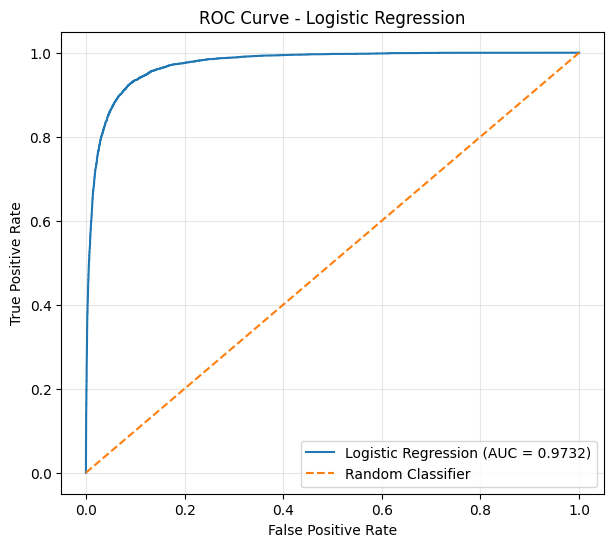

In [52]:
# ROC-AUC CURVE

fpr, tpr, thresholds = roc_curve(
    y_valid,
    y_valid_proba
)

roc_auc_curve = roc_auc_score(
    y_valid,
    y_valid_proba
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_curve:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [53]:
# LOGISTIC REGRESSION — WITHOUT CLASS BALANCING


# Create Logistic Regression model
logistic_model2 = LogisticRegression(
    max_iter=1000,
    random_state=607
)

# Fit model
logistic_model2.fit(X_train_final, y_train)

# Predictions
y_pred_logreg = logistic_model2.predict(X_valid_final)

# Probability predictions for ROC-AUC
y_prob_logreg = logistic_model2.predict_proba(X_valid_final)[:, 1]

# METRICS

accuracy = accuracy_score(y_valid, y_pred_logreg)
precision = precision_score(y_valid, y_pred_logreg)
recall = recall_score(y_valid, y_pred_logreg)
f1 = f1_score(y_valid, y_pred_logreg)
roc_auc = roc_auc_score(y_valid, y_prob_logreg)

print("========== LOGISTIC REGRESSION (WITHOUT BALANCING) ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_valid, y_pred_logreg))

print("========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_valid, y_pred_logreg))



========== LOGISTIC REGRESSION (WITHOUT BALANCING) ==========
Accuracy : 0.9377
Precision: 0.8442
Recall   : 0.8062
F1 Score : 0.8247
ROC-AUC  : 0.9732

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     23027
           1       0.84      0.81      0.82      5113

    accuracy                           0.94     28140
   macro avg       0.90      0.89      0.89     28140
weighted avg       0.94      0.94      0.94     28140

========== CONFUSION MATRIX ==========
[[22266   761]
 [  991  4122]]


#### SVM

In [54]:
# LINEAR SVM WITH CLASS BALANCING


svm_model1 = LinearSVC(
    class_weight="balanced", 
    max_iter=5000,
    random_state=42
)

# Train ONLY on training data
svm_model1.fit(
    X_train_final,
    y_train
)

# Validation predictions
y_valid_pred_svm = svm_model1.predict(X_valid_final)

# Decision scores for ROC-AUC
y_valid_score_svm = svm_model1.decision_function(X_valid_final)

In [55]:
# LINEAR SVM - VALIDATION METRICS

accuracy_svm = accuracy_score(y_valid, y_valid_pred_svm)
precision_svm = precision_score(y_valid, y_valid_pred_svm)
recall_svm = recall_score(y_valid, y_valid_pred_svm)
f1_svm = f1_score(y_valid, y_valid_pred_svm)
auc_svm = roc_auc_score(y_valid, y_valid_score_svm)

print("========== LINEAR SVM ==========")
print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1 Score : {f1_svm:.4f}")
print(f"ROC-AUC  : {auc_svm:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_valid, y_valid_pred_svm))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_valid, y_valid_pred_svm))

========== LINEAR SVM ==========
Accuracy : 0.9135
Precision: 0.6974
Recall   : 0.9259
F1 Score : 0.7956
ROC-AUC  : 0.9732

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.98      0.91      0.95     23027
           1       0.70      0.93      0.80      5113

    accuracy                           0.91     28140
   macro avg       0.84      0.92      0.87     28140
weighted avg       0.93      0.91      0.92     28140


========== CONFUSION MATRIX ==========
[[20973  2054]
 [  379  4734]]


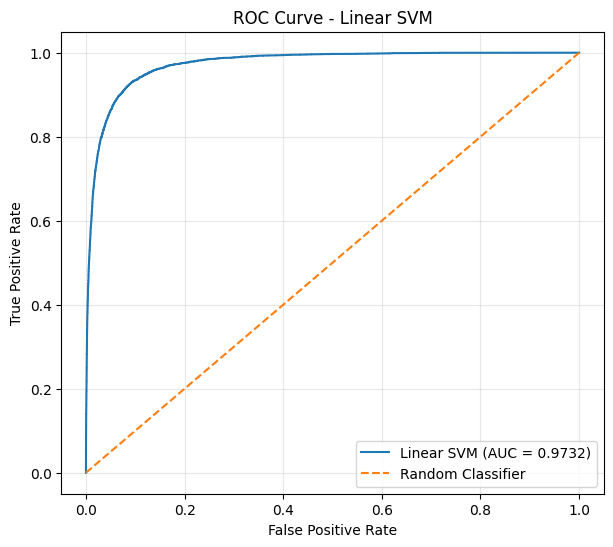

In [56]:
# ROC CURVE - LINEAR SVM


fpr_svm, tpr_svm, thresholds_svm = roc_curve(
    y_valid,
    y_valid_score_svm
)

roc_auc_svm = roc_auc_score(
    y_valid,
    y_valid_score_svm
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"Linear SVM (AUC = {roc_auc_svm:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Linear SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [57]:
# LINEAR SVM — WITHOUT CLASS BALANCING

svm_model2 = LinearSVC(
    random_state=607,
    max_iter=5000
)

# Fit model
svm_model2.fit(X_train_final, y_train)

# Predictions
y_pred_svm = svm_model2.predict(X_valid_final)

# Decision scores for ROC-AUC
y_score_svm = svm_model2.decision_function(X_valid_final)

# METRICS

accuracy = accuracy_score(y_valid, y_pred_svm)
precision = precision_score(y_valid, y_pred_svm)
recall = recall_score(y_valid, y_pred_svm)
f1 = f1_score(y_valid, y_pred_svm)
roc_auc = roc_auc_score(y_valid, y_score_svm)

print("========== LINEAR SVM (WITHOUT BALANCING) ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_valid, y_pred_svm))

print("========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_valid, y_pred_svm))


========== LINEAR SVM (WITHOUT BALANCING) ==========
Accuracy : 0.9381
Precision: 0.8428
Recall   : 0.8103
F1 Score : 0.8262
ROC-AUC  : 0.9732

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     23027
           1       0.84      0.81      0.83      5113

    accuracy                           0.94     28140
   macro avg       0.90      0.89      0.89     28140
weighted avg       0.94      0.94      0.94     28140

========== CONFUSION MATRIX ==========
[[22254   773]
 [  970  4143]]


##### Kernel Trick

In [58]:
# POLYNOMIAL KERNEL SVM

# 1. Create a stratified subset for Kernel SVM

X_train_kernel, _, y_train_kernel, _ = train_test_split(
    X_train_final,
    y_train,
    train_size=20000,
    stratify=y_train,
    random_state=607
)

print("Kernel SVM training data:", X_train_kernel.shape)
print("Kernel SVM target:", y_train_kernel.shape)


# 2. Polynomial Kernel SVM

model_poly = SVC(
    kernel="poly",
    degree=2,
    C=1.0,
    gamma="scale",
    coef0=1.0
)

model_poly.fit(
    X_train_kernel,
    y_train_kernel
)


# 3. Predictions

y_pred_poly = model_poly.predict(X_valid_final)

# Decision function for ROC-AUC
y_score_poly = model_poly.decision_function(
    X_valid_final
)

# 4. Evaluation Metrics

accuracy_poly = accuracy_score(
    y_valid,
    y_pred_poly
)

precision_poly = precision_score(
    y_valid,
    y_pred_poly
)

recall_poly = recall_score(
    y_valid,
    y_pred_poly
)

f1_poly = f1_score(
    y_valid,
    y_pred_poly
)

roc_auc_poly = roc_auc_score(
    y_valid,
    y_score_poly
)


# 5. Print Results

print("\n========== POLYNOMIAL KERNEL SVM ==========")

print(f"Accuracy : {accuracy_poly:.4f}")
print(f"Precision: {precision_poly:.4f}")
print(f"Recall   : {recall_poly:.4f}")
print(f"F1 Score : {f1_poly:.4f}")
print(f"ROC-AUC  : {roc_auc_poly:.4f}")


print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_valid,
        y_pred_poly
    )
)


print("========== CONFUSION MATRIX ==========")

print(
    confusion_matrix(
        y_valid,
        y_pred_poly
    )
)

Kernel SVM training data: (20000, 17)
Kernel SVM target: (20000,)

========== POLYNOMIAL KERNEL SVM ==========
Accuracy : 0.9383
Precision: 0.8486
Recall   : 0.8036
F1 Score : 0.8255
ROC-AUC  : 0.9697

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     23027
           1       0.85      0.80      0.83      5113

    accuracy                           0.94     28140
   macro avg       0.90      0.89      0.89     28140
weighted avg       0.94      0.94      0.94     28140

========== CONFUSION MATRIX ==========
[[22294   733]
 [ 1004  4109]]


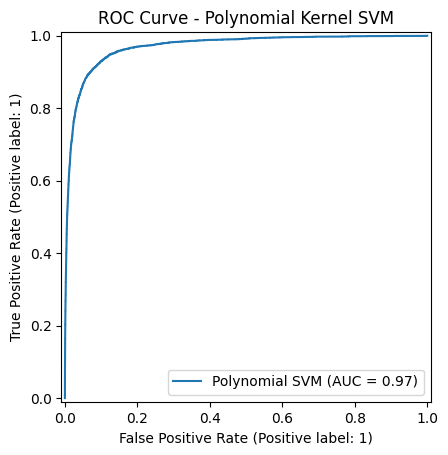

In [59]:
# ROC CURVE — POLYNOMIAL KERNEL SVM

RocCurveDisplay.from_predictions(
    y_valid,
    y_score_poly,
    name="Polynomial SVM"
)

plt.title("ROC Curve - Polynomial Kernel SVM")
plt.show()

#### KNN

In [60]:
# K-NEAREST NEIGHBORS (KNN)


knn_model= KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    n_jobs=-1
)

knn_model.fit(
    X_train_final,
    y_train
)

# 2. Predictions

y_pred_knn = knn_model.predict(
    X_valid_final
)

# Probability of positive class for ROC-AUC
y_prob_knn = knn_model.predict_proba(
    X_valid_final
)[:, 1]


# 3. Metrics

accuracy_knn = accuracy_score(
    y_valid,
    y_pred_knn
)

precision_knn = precision_score(
    y_valid,
    y_pred_knn
)

recall_knn = recall_score(
    y_valid,
    y_pred_knn
)

f1_knn = f1_score(
    y_valid,
    y_pred_knn
)

roc_auc_knn = roc_auc_score(
    y_valid,
    y_prob_knn
)


# 4. Results

print("========== K-NEAREST NEIGHBORS ==========")

print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1 Score : {f1_knn:.4f}")
print(f"ROC-AUC  : {roc_auc_knn:.4f}")


print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_valid,
        y_pred_knn
    )
)


print("========== CONFUSION MATRIX ==========")

print(
    confusion_matrix(
        y_valid,
        y_pred_knn
    )
)

========== K-NEAREST NEIGHBORS ==========
Accuracy : 0.9275
Precision: 0.8084
Recall   : 0.7880
F1 Score : 0.7981
ROC-AUC  : 0.9407

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     23027
           1       0.81      0.79      0.80      5113

    accuracy                           0.93     28140
   macro avg       0.88      0.87      0.88     28140
weighted avg       0.93      0.93      0.93     28140

========== CONFUSION MATRIX ==========
[[22072   955]
 [ 1084  4029]]


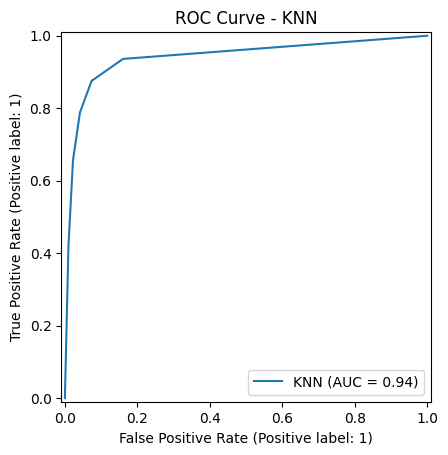

In [61]:
# ROC CURVE — KNN

RocCurveDisplay.from_predictions(
    y_valid,
    y_prob_knn,
    name="KNN"
)

plt.title("ROC Curve - KNN")
plt.show()

#### Comparing Models

In [62]:
# MODEL COMPARISON — VALIDATION SET

models = {
    "Logistic Regression 1": logistic_model1,
    "Logistic Regression 2": logistic_model2,
    "SVM 1": svm_model1,
    "SVM 2": svm_model2,
    "KNN": knn_model
}

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_valid_final)

    # Scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_valid_final)[:, 1]
    else:
        y_score = model.decision_function(X_valid_final)

    # Metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(y_valid, y_pred),
        "Recall": recall_score(y_valid, y_pred),
        "F1 Score": f1_score(y_valid, y_pred),
        "ROC-AUC": roc_auc_score(y_valid, y_score)
    })


# COMPARISON TABLE

comparison = pd.DataFrame(results)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison[metrics] = comparison[metrics].round(4)

print("========== MODEL COMPARISON ==========")

display(comparison)


# OVERALL SCORE

comparison["Overall Score"] = (
    comparison[metrics].mean(axis=1)
)

comparison["Overall Score"] = comparison[
    "Overall Score"
].round(4)

comparison = comparison.sort_values(
    "Overall Score",
    ascending=False
).reset_index(drop=True)


print("\n========== MODEL RANKING ==========")

display(comparison)


# BEST MODEL

print("\n========== BEST MODEL ==========")

print(
    "Best model:",
    comparison.loc[0, "Model"]
)

print(
    "Overall Score:",
    comparison.loc[0, "Overall Score"]
)

========== MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression 1,0.9146,0.7010,0.9239,0.7972,0.9732
1,Logistic Regression 2,0.9377,0.8442,0.8062,0.8247,0.9732
2,SVM 1,0.9135,0.6974,0.9259,0.7956,0.9732
3,SVM 2,0.9381,0.8428,0.8103,0.8262,0.9732
4,KNN,0.9275,0.8084,0.7880,0.7981,0.9407



========== MODEL RANKING ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Overall Score
0,SVM 2,0.9381,0.8428,0.8103,0.8262,0.9732,0.8781
1,Logistic Regression 2,0.9377,0.8442,0.8062,0.8247,0.9732,0.8772
2,Logistic Regression 1,0.9146,0.7010,0.9239,0.7972,0.9732,0.8620
3,SVM 1,0.9135,0.6974,0.9259,0.7956,0.9732,0.8611
4,KNN,0.9275,0.8084,0.7880,0.7981,0.9407,0.8525



========== BEST MODEL ==========
Best model: SVM 2
Overall Score: 0.8781


In [63]:
# AUTOMATIC BEST MODEL SELECTION

best_model_name = comparison.loc[0, "Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Overall Score :", comparison.loc[0, "Overall Score"])

Selected model: SVM 2
Overall Score : 0.8781


### Test Fitting

In [64]:
# TEST IDs

test_ids = test["id"].copy()

print("Number of test IDs:", len(test_ids))
print("Number of test observations:", len(X_test_final))

Number of test IDs: 93800
Number of test observations: 93800


In [65]:
# FINAL TEST PREDICTION

final_model = final_model = best_model

test_predictions = final_model.predict(X_test_final)

print("Number of predictions:", len(test_predictions))
print("Prediction distribution:")
print(pd.Series(test_predictions).value_counts())

Number of predictions: 93800
Prediction distribution:
0    77358
1    16442
Name: count, dtype: int64


In [66]:
# TEST PREDICTIONS WITH IDS

test_results = pd.DataFrame({
    "id": test_ids.values,
    "depression": test_predictions
})

print("========== FINAL TEST RESULTS ==========")
display(test_results.head(10))

print("\nShape:", test_results.shape)

print("\nMissing values:")
print(test_results.isna().sum())

print("\nUnique IDs:", test_results["id"].nunique())

========== FINAL TEST RESULTS ==========


,id,depression
0,140700,0
1,140701,0
2,140702,0
3,140703,1
4,140704,0
5,140705,0
6,140706,0
7,140707,0
8,140708,0
9,140709,1



Shape: (93800, 2)

Missing values:
id            0
depression    0
dtype: int64

Unique IDs: 93800


In [67]:
# SAVE FINAL KAGGLE SUBMISSION

submission = test_results[["id", "depression"]].copy()

submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission file created successfully!")
print("Shape:", submission.shape)
print("\nFirst 10 rows:")
display(submission.head(10))

Submission file created successfully!
Shape: (93800, 2)

First 10 rows:


,id,depression
0,140700,0
1,140701,0
2,140702,0
3,140703,1
4,140704,0
5,140705,0
6,140706,0
7,140707,0
8,140708,0
9,140709,1


In [68]:
# FINAL SUBMISSION CHECK

submission_check = pd.read_csv("submission.csv")

print("Shape:", submission_check.shape)
print("Columns:", submission_check.columns.tolist())
print("Missing values:")
print(submission_check.isna().sum())

print("\nUnique IDs:", submission_check["id"].nunique())

print("\nFirst 10 rows:")
display(submission_check.head(10))

Shape: (93800, 2)
Columns: ['id', 'depression']
Missing values:
id            0
depression    0
dtype: int64

Unique IDs: 93800

First 10 rows:


,id,depression
0,140700,0
1,140701,0
2,140702,0
3,140703,1
4,140704,0
5,140705,0
6,140706,0
7,140707,0
8,140708,0
9,140709,1
